# Khmer Emotion Classification

**Course:** ITM 454 002  
**Task:** Seven-class Khmer emotion classification  
**Main metric:** Macro-F1 on the held-out test set

For this project, we compare two approaches for classifying Khmer sentences as angry, fear, happy, lonely, neutral, sad, or stress. The first is a TF-IDF and Logistic Regression baseline; the second is XLM-RoBERTa fine-tuned on the same data split.

The three raw Parquet files contain about 4.2 million rows, including many repeated or closely related sentences. We clean and de-duplicate the corpus before creating an 80/10/10 split. Similar template families stay in one partition so they cannot appear in both training and testing. We also evaluate both models on 42 Khmer sentences written separately from the corpus.

## Notebook outline

| Section | Work included |
|---|---|
| 0 | Environment and experiment settings |
| P1–P7 | Cleaning, de-duplication, balancing, grouping, and splitting |
| 1 | Dataset overview |
| 2 | Evaluation functions |
| 3 | TF-IDF and Logistic Regression baseline |
| 4 | XLM-RoBERTa fine-tuning |
| 5 | Comparison on the held-out test set |
| 6 | Evaluation on independently written sentences |
| 7 | Sample predictions and saved outputs |
| 8 | Result summary and limitations |
| 9 | Additional random-seed runs |
| 10 | Export to Google Drive |

## How to run

1. Put `train-00000-of-00003.parquet`, `train-00001-of-00003.parquet`, and `train-00002-of-00003.parquet` in `My Drive/KhmerEmotionFinal/`.
2. In Google Colab, select **Runtime → Change runtime type → T4 GPU**.
3. Run from the first cell and allow Drive access when prompted.
4. Data preparation may take about one hour on Colab. The main XLM-R run usually takes 7–10 minutes on a T4, while the optional extra-seed runs add about 15–20 minutes.
5. When the run is complete, use **File → Download → Download .ipynb** to save the notebook with its outputs.

Large intermediate files are kept in Colab's temporary storage. Result tables, figures, and other small files are copied to `My Drive/KhmerEmotionFinal/full_submission_results/` near the end of the notebook.

## Workflow

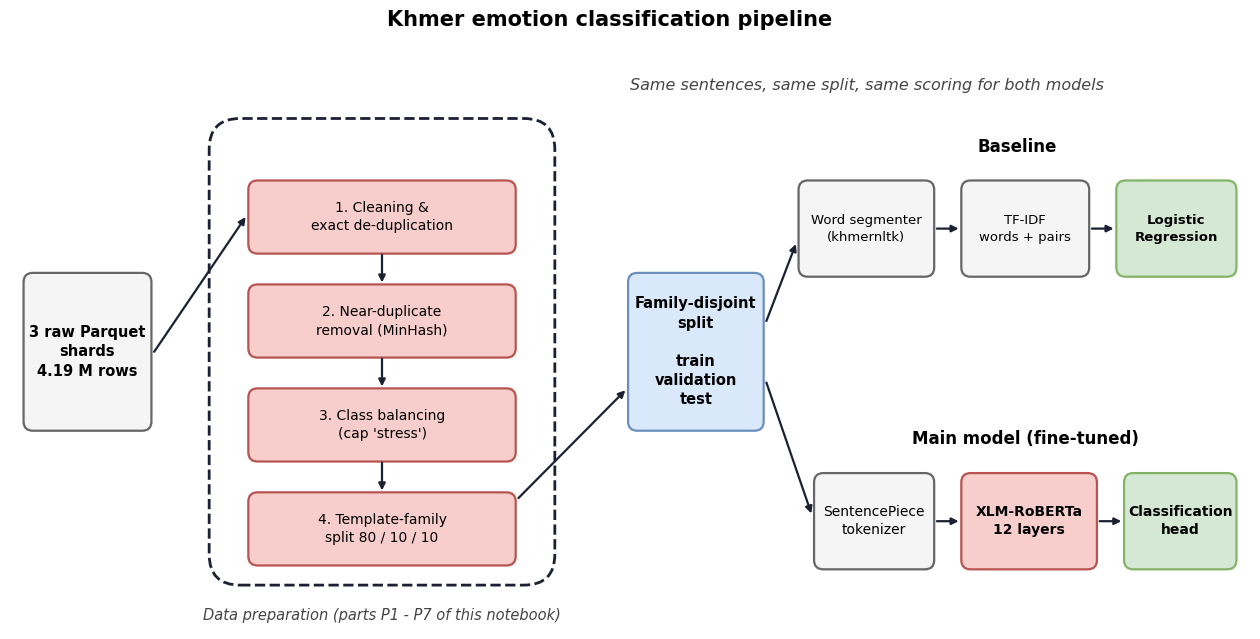

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def _box(ax, x, y, w, h, text, fc, ec, size=10.5, bold=False, rx=1.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0.25,rounding_size={rx}", fc=fc, ec=ec, lw=1.6))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size, fontweight="bold" if bold else "normal", linespacing=1.35)

def _arrow(ax, x0, y0, x1, y1, color="#1B2033", style="-|>"):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle=style, lw=1.6, color=color, shrinkA=0, shrinkB=0))

def draw_pipeline():
    GRAY, PINK, BLUE, GREEN = ("#F5F5F5", "#666666"), ("#F8CECC", "#B85450"), ("#DAE8FC", "#6C8EBF"), ("#D5E8D4", "#82B366")
    fig, ax = plt.subplots(figsize=(16, 7.2))
    ax.set_xlim(0, 160); ax.set_ylim(0, 72); ax.axis("off")

    _box(ax, 2, 26, 16, 20, "3 raw Parquet\nshards\n4.19 M rows", *GRAY, bold=True)
    ax.add_patch(FancyBboxPatch((26, 6), 44, 60, boxstyle="round,pad=0.3,rounding_size=4", fc="none", ec="#1B2033", lw=2, ls="--"))
    steps = ["1. Cleaning &\nexact de-duplication", "2. Near-duplicate\nremoval (MinHash)", "3. Class balancing\n(cap 'stress')", "4. Template-family\nsplit 80 / 10 / 10"]
    for i, s in enumerate(steps):
        y = 49 - i * 13.5
        _box(ax, 31, y, 34, 9, s, *PINK, size=10)
        if i < 3: _arrow(ax, 48, y - 0.4, 48, y - 4.0)
    ax.text(48, 1.2, "Data preparation (parts P1 - P7 of this notebook)", ha="center", fontsize=10.5, style="italic", color="#444")
    _arrow(ax, 18.6, 36, 30.4, 53.5)

    _box(ax, 80, 26, 17, 20, "Family-disjoint\nsplit\n\ntrain\nvalidation\ntest", *BLUE, bold=True)
    _arrow(ax, 65.6, 17, 79.4, 31)

    _box(ax, 102, 46, 17, 12, "Word segmenter\n(khmernltk)", *GRAY, size=9.5)
    _box(ax, 123, 46, 16, 12, "TF-IDF\nwords + pairs", *GRAY, size=9.5)
    _box(ax, 143, 46, 15, 12, "Logistic\nRegression", *GREEN, size=9.5, bold=True)
    ax.text(130, 62, "Baseline", ha="center", fontsize=12, fontweight="bold")
    _arrow(ax, 97.6, 40, 101.4, 50); _arrow(ax, 119.6, 52, 122.4, 52); _arrow(ax, 139.6, 52, 142.4, 52)

    _box(ax, 104, 8, 15, 12, "SentencePiece\ntokenizer", *GRAY, size=10)
    _box(ax, 123, 8, 17, 12, "XLM-RoBERTa\n12 layers", *PINK, size=10, bold=True)
    _box(ax, 144, 8, 14, 12, "Classification\nhead", *GREEN, size=10, bold=True)
    ax.text(131, 24, "Main model (fine-tuned)", ha="center", fontsize=12, fontweight="bold")
    _arrow(ax, 97.6, 32, 103.4, 15); _arrow(ax, 119.6, 14, 122.4, 14); _arrow(ax, 140.6, 14, 143.4, 14)
    ax.text(80, 70, "Same sentences, same split, same scoring for both models", fontsize=11.5, style="italic", color="#444")
    fig.suptitle("Khmer emotion classification pipeline", fontsize=15, fontweight="bold", y=0.97)
    return fig

fig = draw_pipeline(); plt.show()

## 0. Setup

The experiment uses Hugging Face Transformers and Datasets, PyTorch, scikit-learn, `khmer-nltk`, and the libraries needed for corpus processing. Scikit-learn is pinned to 1.6.1 because changes to `StratifiedGroupKFold` can produce a different group split. If Colab requests a restart after installation, restart the runtime and run again from the top.

In [2]:
%pip install -q "transformers>=4.46,<5" "datasets>=3,<5" "accelerate>=1,<2" sentencepiece "scikit-learn==1.6.1" pandas pyarrow scipy matplotlib seaborn joblib tqdm datasketch khmer-nltk

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


### Configuration

All shared settings are kept here: labels, paths, preprocessing thresholds, random seeds, bootstrap repetitions, and XLM-R training parameters.

In [3]:
from pathlib import Path
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import gc
import hashlib
import importlib.metadata as metadata
import json
import math
import platform
import re
import shutil
import sqlite3
import sys
import time
import unicodedata
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
import torch
from datasets import Dataset, DatasetDict
from IPython.display import display
from khmernltk import word_tokenize as khmer_word_tokenize   # Khmer word segmenter used by the baseline
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from tqdm.auto import tqdm
from transformers import (
    AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
    EarlyStoppingCallback, Trainer, TrainingArguments, set_seed,
)

# Paths and storage options
DATA_DIR_OVERRIDE = None      # optional path to the three Parquet shards
SAVE_MODEL_TO_DRIVE = False   # include the model during the main Drive export
KEEP_CHECKPOINTS = False      # retain intermediate training checkpoints when enabled

# Reference values from the original run
EXPECTED_ROWS = 7_558
EXPECTED_FINGERPRINT = "153b49c5ba58b2dd10c9e754eeaf63ae5c054b9011208523e1d88b62c4a4db34"

@dataclass(frozen=True)
class Config:
    seed: int = 42
    # Data preparation
    pipeline_version: str = "balanced-near-v2"
    near_duplicate_threshold: float = 0.65    # Jaccard threshold for character 5-gram pairs
    shingle_size: int = 5
    minhash_permutations: int = 128
    template_similarity: float = 0.80         # cosine threshold on emotion-masked TF-IDF vectors
    template_neighbors: int = 6
    # XLM-RoBERTa
    model_name: str = "FacebookAI/xlm-roberta-base"
    epochs: int = 3
    learning_rate: float = 2e-5
    train_batch_size: int = 8
    eval_batch_size: int = 16
    gradient_accumulation_steps: int = 2      # 8 x 2 = an effective batch of 16 sentences
    max_length: int = 144                     # maximum sequence length in subword tokens
    weight_decay: float = 0.01
    warmup_ratio: float = 0.10
    # TF-IDF baseline
    word_ngram_range: tuple = (1, 2)          # single words and pairs of neighbouring words
    max_features: int = 300_000
    c_grid: tuple = (0.1, 1, 10, 100, 1000)   # validation-set regularization candidates
    # Uncertainty estimation
    bootstrap_repeats: int = 2_000

CFG = Config()

LABELS = ["angry", "fear", "happy", "lonely", "neutral", "sad", "stress"]
label2id = {label: index for index, label in enumerate(LABELS)}
id2label = {index: label for label, index in label2id.items()}
LABEL_IDS = list(range(len(LABELS)))

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"baseline": "#8A93A6", "xlmr": "#3F54D1", "wrong": "#D9622B",
          "train": "#6C8EE8", "validation": "#F0A63A", "test": "#4DB57E"}

set_seed(CFG.seed)
np.random.seed(CFG.seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print(json.dumps(asdict(CFG), indent=2))

{
  "seed": 42,
  "pipeline_version": "balanced-near-v2",
  "near_duplicate_threshold": 0.65,
  "shingle_size": 5,
  "minhash_permutations": 128,
  "template_similarity": 0.8,
  "template_neighbors": 6,
  "model_name": "FacebookAI/xlm-roberta-base",
  "epochs": 3,
  "learning_rate": 2e-05,
  "train_batch_size": 8,
  "eval_batch_size": 16,
  "gradient_accumulation_steps": 2,
  "max_length": 144,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "word_ngram_range": [
    1,
    2
  ],
  "max_features": 300000,
  "c_grid": [
    0.1,
    1,
    10,
    100,
    1000
  ],
  "bootstrap_repeats": 2000
}


### Paths and runtime checks

In Colab, the raw files are read from Google Drive while large intermediate files stay under `/content/khmer_work`. Local runs use the current project folder. Training requires a GPU, so the run stops here if no GPU or input shard is found.

In [4]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/KhmerEmotionFinal")
    WORK_DIR = Path("/content/khmer_work")
else:
    DATA_DIR = Path.cwd()
    WORK_DIR = Path.cwd() / "khmer_work"
if DATA_DIR_OVERRIDE:
    DATA_DIR = Path(DATA_DIR_OVERRIDE)

FILES = [DATA_DIR / f"train-{index:05d}-of-00003.parquet" for index in range(3)]
missing_files = [str(path) for path in FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Missing the original Parquet shards: {missing_files}\n"
        "Put train-00000-of-00003.parquet, train-00001-of-00003.parquet and train-00002-of-00003.parquet "
        "in My Drive/KhmerEmotionFinal/ (or set DATA_DIR_OVERRIDE in the configuration cell).")

HAS_GPU = torch.cuda.is_available()
if not HAS_GPU:
    raise RuntimeError("No GPU found. In Colab choose Runtime > Change runtime type > T4 GPU, then run again.")
print("GPU:", torch.cuda.get_device_name(0))

RESULTS_DIR = DATA_DIR / "full_submission_results"        # final Drive export directory
OUT_DIR = WORK_DIR / "results"                            # local result directory
PREP_OUT = OUT_DIR / "preprocessing"
XLMR_OUT, BASE_OUT, COMPARE_OUT = (OUT_DIR / name for name in ("xlmr", "baseline", "comparison"))
INTERMEDIATE = WORK_DIR / "intermediate"                  # local intermediate directory
CHECKPOINT_DIR = WORK_DIR / "xlmr_checkpoints"
FINAL_MODEL_DIR = XLMR_OUT / "xlmr_best_model"
for folder in (PREP_OUT, XLMR_OUT, BASE_OUT, COMPARE_OUT, INTERMEDIATE, CHECKPOINT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

versions = {p: metadata.version(p) for p in ["torch", "transformers", "datasets", "accelerate", "pandas", "scikit-learn", "datasketch", "khmer-nltk"]}
print("Python:", platform.python_version(), "| packages:", versions)
if versions["scikit-learn"] != "1.6.1":
    warnings.warn(f"scikit-learn {versions['scikit-learn']} is installed, but the original experiment used 1.6.1. "
                  "The data split will probably differ from the original one (see the fingerprint check in P7).")
print("Free disk space on Colab:", f"{shutil.disk_usage(WORK_DIR).free / 1e9:.0f} GB")
print("\nREAD-ONLY input :", DATA_DIR)
print("Working folder  :", WORK_DIR, "(temporary)")
print("Final results   :", RESULTS_DIR, "(small files, copied at the end)")

Mounted at /content/drive
GPU: Tesla T4
Python: 3.13.16 | packages: {'torch': '2.14.1+cu130', 'transformers': '4.57.6', 'datasets': '4.8.5', 'accelerate': '1.15.0', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'datasketch': '2.0.0', 'khmer-nltk': '1.6'}
Free disk space on Colab: 121 GB

READ-ONLY input : /content/drive/MyDrive/KhmerEmotionFinal
Working folder  : /content/khmer_work (temporary)
Final results   : /content/drive/MyDrive/KhmerEmotionFinal/full_submission_results (small files, copied at the end)


## Preparing the corpus

Most of the raw corpus is repeated or template-based. Preparation is therefore done before any model is trained: normalize the text, remove exact and near-duplicates, limit the oversized stress class, group related templates, and split by group.

### P1. Input fingerprint

We record each shard's hash, size, row count, and schema before processing. This manifest fixes the exact version of the raw corpus used in the run.

In [5]:
def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while chunk := handle.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

manifest = {
    "pipeline_version": CFG.pipeline_version,
    "labels": LABELS,
    "files": [
        {
            "file": path.name,
            "rows": pq.ParquetFile(path).metadata.num_rows,
            "bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "schema": str(pq.ParquetFile(path).schema_arrow),
        }
        for path in FILES
    ],
}
manifest_fingerprint = hashlib.sha256(
    json.dumps(manifest, sort_keys=True).encode("utf-8")
).hexdigest()

display(pd.DataFrame(manifest["files"])[["file", "rows", "bytes", "sha256"]])
print("Input/pipeline fingerprint:", manifest_fingerprint)
(PREP_OUT / "input_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

,file,rows,bytes,sha256
0,train-00000-of-00003.parquet,1395030,47309910,c0c1b968e27608bf025c64add0f31b682e0df379516ed6...
1,train-00001-of-00003.parquet,1395030,32843138,a09d086a9a83ac9e8ac3c0520e6e029b330f5e38ec7170...
2,train-00002-of-00003.parquet,1395030,80645559,fc4e1ba829ea5870338e4dddb5198022f6d44e45661b2d...


Input/pipeline fingerprint: 35c830b7eabc10b634ec8f420b8f471570bb511f285765d3405abb35df1a694a


1269

### P2. Text normalization

Khmer text is normalized to Unicode NFC, invisible separators are replaced, and repeated whitespace is collapsed. Known counters added by the dataset generator are removed only when they occur as verified suffix patterns. A version without whitespace is used as the exact-match key; the original example is kept for auditing.

In [6]:
SPACE_RE = re.compile(r"\s+")
INVISIBLE_SEPARATORS_RE = re.compile(r"[\u200b\u200c\u200d\ufeff]")
KHMER_RE = re.compile(r"[\u1780-\u17FF]")
BARE_COUNTER_RE = re.compile(
    r"[\s\u200b\u200c\u200d\ufeff]*\(([0-9០-៩]+)\)"
    r"[\s\u200b\u200c\u200d\ufeff]*$"
)
GENERATOR_MARKER_RE = re.compile(
    r"[\s\u200b\u200c\u200d\ufeff]*"
    r"\((?:ការគិតអប់រំចិត្តទី|ករណីសិក្សាទី|ករណីទី)\s*[0-9០-៩]+\)"
    r"[\s\u200b\u200c\u200d\ufeff]*$"
)

@lru_cache(maxsize=200_000)
def normalize_base(value):
    value = unicodedata.normalize("NFC", value)
    value = INVISIBLE_SEPARATORS_RE.sub(" ", value)
    value = "".join(" " if unicodedata.category(ch) == "Cc" else ch for ch in value)
    return SPACE_RE.sub(" ", value).strip()

def remove_generated_suffix(value):
    marker = GENERATOR_MARKER_RE.search(value)
    if marker:
        return GENERATOR_MARKER_RE.sub("", value).strip(), marker.group(0).strip(), "generator_marker"
    counter = BARE_COUNTER_RE.search(value)
    if counter:
        return BARE_COUNTER_RE.sub("", value).strip(), counter.group(0).strip(), "bare_counter"
    return value, None, None

def canonical_key(value):
    return SPACE_RE.sub("", value)

def prepare_text(raw_text):
    base = normalize_base(raw_text)
    model_text, removed_suffix, removal_rule = remove_generated_suffix(base)
    return {
        "base_text": base,
        "model_text": model_text,
        "pre_suffix_key": canonical_key(base),
        "dedup_key": canonical_key(model_text),
        "removed_suffix": removed_suffix,
        "removal_rule": removal_rule,
    }

examples = [
    "ខ្ញុំសប្បាយចិត្តណាស់។ (1)",
    "ខ្ញុំមានអារម្មណ៍សោកសៅ។ (ករណីសិក្សាទី 10)",
    "ខ្ញុំមានអារម្មណ៍ខឹង។ (ការគិតអប់រំចិត្តទី 66972)",
]
display(pd.DataFrame([{"raw": text, **prepare_text(text)} for text in examples]))

,raw,base_text,model_text,pre_suffix_key,dedup_key,removed_suffix,removal_rule
0,ខ្ញុំសប្បាយចិត្តណាស់។ (1),ខ្ញុំសប្បាយចិត្តណាស់។ (1),ខ្ញុំសប្បាយចិត្តណាស់។,ខ្ញុំសប្បាយចិត្តណាស់។(1),ខ្ញុំសប្បាយចិត្តណាស់។,(1),bare_counter
1,ខ្ញុំមានអារម្មណ៍សោកសៅ។ (ករណីសិក្សាទី 10),ខ្ញុំមានអារម្មណ៍សោកសៅ។ (ករណីសិក្សាទី 10),ខ្ញុំមានអារម្មណ៍សោកសៅ។,ខ្ញុំមានអារម្មណ៍សោកសៅ។(ករណីសិក្សាទី10),ខ្ញុំមានអារម្មណ៍សោកសៅ។,(ករណីសិក្សាទី 10),generator_marker
2,ខ្ញុំមានអារម្មណ៍ខឹង។ (ការគិតអប់រំចិត្តទី 66972),ខ្ញុំមានអារម្មណ៍ខឹង។ (ការគិតអប់រំចិត្តទី 66972),ខ្ញុំមានអារម្មណ៍ខឹង។,ខ្ញុំមានអារម្មណ៍ខឹង។(ការគិតអប់រំចិត្តទី66972),ខ្ញុំមានអារម្មណ៍ខឹង។,(ការគិតអប់រំចិត្តទី 66972),generator_marker


### P3. Exact de-duplication

The shards are scanned in batches and merged into a temporary SQLite table by normalized text key. Repeated copies are counted rather than loaded into memory. Texts assigned to more than one label are marked as conflicts and excluded.

In [7]:
DB_PATH = INTERMEDIATE / "deduplicated.sqlite"
AUDIT_PATH = PREP_OUT / "data_audit.json"
for suffix in ("", "-wal", "-shm"):
    candidate = Path(str(DB_PATH) + suffix)
    if candidate.exists():
        candidate.unlink()

db = sqlite3.connect(DB_PATH)
db.execute("PRAGMA journal_mode=WAL")
db.execute("PRAGMA synchronous=NORMAL")
db.execute("""
    CREATE TABLE texts (
        dedup_key TEXT PRIMARY KEY,
        model_text TEXT NOT NULL,
        raw_example TEXT NOT NULL,
        label_mask INTEGER NOT NULL,
        copies INTEGER NOT NULL,
        suffix_copies INTEGER NOT NULL,
        first_id TEXT NOT NULL,
        first_file TEXT NOT NULL
    )
""")
db.execute("CREATE TABLE pre_suffix_keys (key TEXT PRIMARY KEY)")
upsert = """
    INSERT INTO texts VALUES (?, ?, ?, ?, ?, ?, ?, ?)
    ON CONFLICT(dedup_key) DO UPDATE SET
        label_mask = texts.label_mask | excluded.label_mask,
        copies = texts.copies + excluded.copies,
        suffix_copies = texts.suffix_copies + excluded.suffix_copies
"""

rejected = Counter()
raw_labels = Counter()
raw_rows = 0
rows_with_generated_suffix = 0
generated_suffix_examples = []
started = time.perf_counter()

for path in FILES:
    parquet_file = pq.ParquetFile(path)
    progress = tqdm(
        parquet_file.iter_batches(batch_size=50_000, columns=["id", "text", "label"]),
        total=math.ceil(parquet_file.metadata.num_rows / 50_000),
        desc=f"Audit {path.name}",
    )
    for batch in progress:
        rows = batch.to_pydict()
        grouped = {}
        pre_suffix_batch = set()
        for ident, raw_text, label in zip(rows["id"], rows["text"], rows["label"]):
            raw_rows += 1
            label = label.strip().lower() if isinstance(label, str) else "<missing>"
            raw_labels[label] += 1

            if ident is None:
                rejected["missing_id"] += 1
                continue
            if not isinstance(raw_text, str):
                rejected["missing_or_nonstring_text"] += 1
                continue
            if label not in label2id:
                rejected["unexpected_label"] += 1
                continue

            prepared = prepare_text(raw_text)
            model_text = prepared["model_text"]
            if not model_text:
                rejected["empty_after_cleaning"] += 1
                continue
            if not KHMER_RE.search(model_text):
                rejected["no_khmer_character"] += 1
                continue

            had_generated_suffix = prepared["removed_suffix"] is not None
            rows_with_generated_suffix += int(had_generated_suffix)
            if had_generated_suffix and len(generated_suffix_examples) < 20:
                generated_suffix_examples.append({
                    "raw_text": raw_text,
                    "model_text": model_text,
                    "removed_suffix": prepared["removed_suffix"],
                    "label": label,
                })

            pre_suffix_batch.add(prepared["pre_suffix_key"])
            key = prepared["dedup_key"]
            mask = 1 << label2id[label]
            if key in grouped:
                grouped[key][3] |= mask
                grouped[key][4] += 1
                grouped[key][5] += int(had_generated_suffix)
            else:
                grouped[key] = [
                    key, model_text, raw_text, mask, 1, int(had_generated_suffix),
                    str(ident), path.name,
                ]

        db.executemany("INSERT OR IGNORE INTO pre_suffix_keys VALUES (?)",
                       [(key,) for key in pre_suffix_batch])
        db.executemany(upsert, grouped.values())
        db.commit()

unique_before_suffix_removal = db.execute("SELECT COUNT(*) FROM pre_suffix_keys").fetchone()[0]
unique_keys, valid_rows = db.execute(
    "SELECT COUNT(*), COALESCE(SUM(copies), 0) FROM texts"
).fetchone()
conflict_keys, conflict_rows = db.execute(
    "SELECT COUNT(*), COALESCE(SUM(copies), 0) FROM texts "
    "WHERE (label_mask & (label_mask - 1)) != 0"
).fetchone()

eligible_by_label = {}
for i, label in id2label.items():
    eligible_by_label[label] = db.execute(
        "SELECT COUNT(*) FROM texts WHERE label_mask = ?", (1 << i,)
    ).fetchone()[0]

audit = {
    "raw_rows": raw_rows,
    "rejected": dict(rejected),
    "valid_rows_before_dedup": valid_rows,
    "unique_keys_before_suffix_removal": unique_before_suffix_removal,
    "unique_keys_after_suffix_removal": unique_keys,
    "unique_keys_collapsed_by_suffix_rules": unique_before_suffix_removal - unique_keys,
    "rows_with_generated_suffix": rows_with_generated_suffix,
    "duplicate_or_artifact_excess_rows": valid_rows - unique_keys,
    "conflicting_keys_excluded": conflict_keys,
    "rows_in_conflicting_keys": conflict_rows,
    "eligible_unique_texts": unique_keys - conflict_keys,
    "raw_label_counts": dict(raw_labels),
    "eligible_unique_by_label": eligible_by_label,
    "generated_suffix_examples": generated_suffix_examples,
    "runtime_minutes": (time.perf_counter() - started) / 60,
}
assert raw_rows == valid_rows + sum(rejected.values())

AUDIT_PATH.write_text(
    json.dumps(audit, ensure_ascii=False, indent=2), encoding="utf-8"
)
db.execute("PRAGMA wal_checkpoint(TRUNCATE)")
db.close()

db = sqlite3.connect(DB_PATH)
print(json.dumps({k: v for k, v in audit.items()
                  if k not in {"generated_suffix_examples"}}, ensure_ascii=False, indent=2))
display(pd.DataFrame(audit["generated_suffix_examples"]).head(10))

Audit train-00000-of-00003.parquet:   0%|          | 0/28 [00:00<?, ?it/s]

Audit train-00001-of-00003.parquet:   0%|          | 0/28 [00:00<?, ?it/s]

Audit train-00002-of-00003.parquet:   0%|          | 0/28 [00:00<?, ?it/s]

{
  "raw_rows": 4185090,
  "rejected": {},
  "valid_rows_before_dedup": 4185090,
  "unique_keys_before_suffix_removal": 1356385,
  "unique_keys_after_suffix_removal": 287284,
  "unique_keys_collapsed_by_suffix_rules": 1069101,
  "rows_with_generated_suffix": 1069450,
  "duplicate_or_artifact_excess_rows": 3897806,
  "conflicting_keys_excluded": 0,
  "rows_in_conflicting_keys": 0,
  "eligible_unique_texts": 287284,
  "raw_label_counts": {
    "fear": 566165,
    "happy": 566485,
    "sad": 566074,
    "stress": 781519,
    "neutral": 571889,
    "angry": 566549,
    "lonely": 566409
  },
  "eligible_unique_by_label": {
    "angry": 9578,
    "fear": 9386,
    "happy": 10152,
    "lonely": 9438,
    "neutral": 14454,
    "sad": 9791,
    "stress": 224485
  },
  "runtime_minutes": 7.900155575566669
}


,raw_text,model_text,removed_suffix,label
0,រាល់ថ្ងៃនេះ មានសម្ពាធពីគ្រប់ទិសទី ទាំងពីគ្រួសា...,រាល់ថ្ងៃនេះ មានសម្ពាធពីគ្រប់ទិសទី ទាំងពីគ្រួសា...,(ករណីសិក្សាទី 10),stress
1,រាល់ថ្ងៃនេះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំម...,រាល់ថ្ងៃនេះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំម...,(ករណីសិក្សាទី 20),fear
2,ពេលខ្លះរឿងរ៉ាវក្នុងអតីតកាលតែងតែត្រឡប់មកធ្វើឱ្យ...,ពេលខ្លះរឿងរ៉ាវក្នុងអតីតកាលតែងតែត្រឡប់មកធ្វើឱ្យ...,(ករណីសិក្សាទី 30),sad
3,ចំពោះខ្ញុំ ពេលយប់ជ្រៅ អារម្មណ៍ឯកោតែងតែវាយលុកចិ...,ចំពោះខ្ញុំ ពេលយប់ជ្រៅ អារម្មណ៍ឯកោតែងតែវាយលុកចិ...,(ករណីសិក្សាទី 40),lonely
4,ពិតណាស់ មានអារម្មណ៍ថាមេឃថ្ងៃនេះស្រឡះល្អ ហើយអ្វ...,ពិតណាស់ មានអារម្មណ៍ថាមេឃថ្ងៃនេះស្រឡះល្អ ហើយអ្វ...,(ករណីសិក្សាទី 50),happy
5,ពេលខ្លះ ពេលដែលគេមិនគោរពពាក្យសន្យា វាធ្វើឱ្យខ្ញ...,ពេលខ្លះ ពេលដែលគេមិនគោរពពាក្យសន្យា វាធ្វើឱ្យខ្ញ...,(ករណីសិក្សាទី 60),angry
6,ចំពោះខ្ញុំ ថ្ងៃនេះជាថ្ងៃធម្មតាមួយ មិនមានអ្វីប្...,ចំពោះខ្ញុំ ថ្ងៃនេះជាថ្ងៃធម្មតាមួយ មិនមានអ្វីប្...,(ករណីសិក្សាទី 70),neutral
7,ចំពោះខ្ញុំ ការងារនិងការសិក្សាគរជើងគ្នាច្រើនពេក...,ចំពោះខ្ញុំ ការងារនិងការសិក្សាគរជើងគ្នាច្រើនពេក...,(ករណីសិក្សាទី 80),stress
8,ពេលខ្លះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំមានអា...,ពេលខ្លះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំមានអា...,(ករណីសិក្សាទី 90),fear
9,និយាយទៅ ខ្ញុំមានអារម្មណ៍សោកសៅនិងខកចិត្តខ្លាំងណ...,និយាយទៅ ខ្ញុំមានអារម្មណ៍សោកសៅនិងខកចិត្តខ្លាំងណ...,(ករណីសិក្សាទី 100),sad


### Exact-match audit

Raw and eligible unique counts are compared by label. We also keep the duplicate/removal fraction and stop if cleaning leaves any class empty.

,raw_rows,eligible_unique_texts,duplicate_or_removed_fraction
angry,566549,9578,0.983094
fear,566165,9386,0.983422
happy,566485,10152,0.982079
lonely,566409,9438,0.983337
neutral,571889,14454,0.974726
sad,566074,9791,0.982704
stress,781519,224485,0.712758


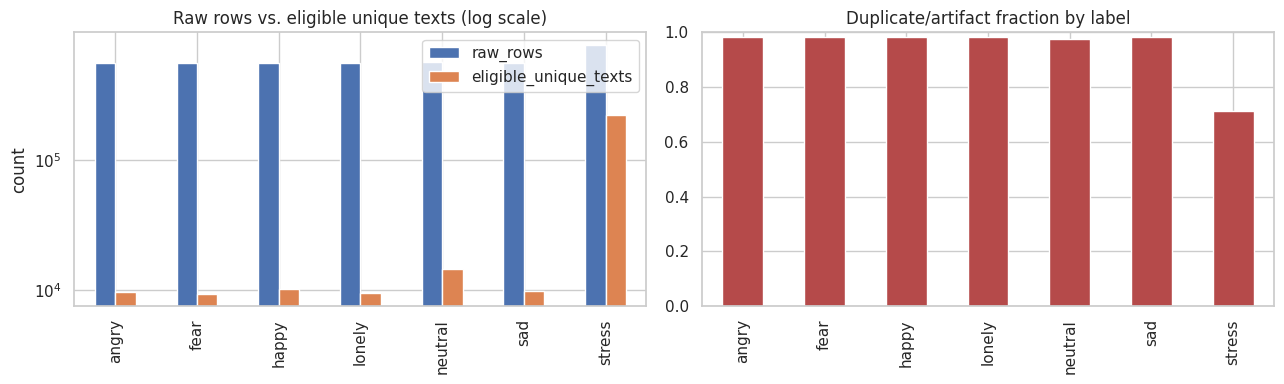

In [8]:
audit_table = pd.DataFrame({
    "raw_rows": pd.Series(audit["raw_label_counts"]),
    "eligible_unique_texts": pd.Series(audit["eligible_unique_by_label"]),
}).reindex(LABELS)
audit_table["duplicate_or_removed_fraction"] = (
    1 - audit_table["eligible_unique_texts"] / audit_table["raw_rows"]
)
display(audit_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
audit_table[["raw_rows", "eligible_unique_texts"]].plot.bar(
    ax=axes[0], logy=True, title="Raw rows vs. eligible unique texts (log scale)"
)
audit_table["duplicate_or_removed_fraction"].plot.bar(
    ax=axes[1], color="#b54a4a", title="Duplicate/artifact fraction by label"
)
axes[1].set_ylim(0, 1)
axes[0].set_ylabel("count")
plt.tight_layout()

if audit["conflicting_keys_excluded"]:
    warnings.warn(
        f'{audit["conflicting_keys_excluded"]:,} exact-text keys have conflicting labels '
        "and will be excluded."
    )
assert (audit_table["eligible_unique_texts"] > 0).all(), (
    "At least one label has no eligible unique text after cleaning."
)

### P4. Clean corpus

All eligible exact-unique sentences are loaded from SQLite without class capping. The cleaned corpus receives its own fingerprint before near-duplicate filtering.

In [9]:
records = []
query = """
    SELECT dedup_key, model_text, raw_example, label_mask, copies,
           suffix_copies, first_id, first_file
    FROM texts
    WHERE (label_mask & (label_mask - 1)) = 0
    ORDER BY dedup_key
"""
for key, text, raw_example, mask, copies, suffix_copies, source_id, source_file in db.execute(query):
    label = id2label[int(mask).bit_length() - 1]
    records.append({
        "text_key": key,
        "text": text,
        "raw_example": raw_example,
        "label": label,
        "original_copies": copies,
        "suffix_copies": suffix_copies,
        "source_id": source_id,
        "source_file": source_file,
    })
corpus = pd.DataFrame(records)
db.close()

assert corpus["text_key"].is_unique
assert set(corpus["label"]) == set(LABELS)
corpus_identity = {
    "pipeline_version": CFG.pipeline_version,
    "seed": CFG.seed,
    "rows": len(corpus),
}
corpus_fingerprint = hashlib.sha256(
    ("|".join(corpus["text_key"]) + "|" + json.dumps(corpus_identity, sort_keys=True))
    .encode("utf-8")
).hexdigest()
display(corpus.groupby("label").agg(
    exact_unique_texts=("text", "size"),
    median_characters=("text", lambda values: int(values.str.len().median())),
    max_original_copies=("original_copies", "max"),
))
print("Exact-unique corpus:", len(corpus))
print("Corpus fingerprint:", corpus_fingerprint)

,exact_unique_texts,median_characters,max_original_copies
label,,,
angry,9578,298,20409
fear,9386,300,20409
happy,10152,279,20409
lonely,9438,306,20409
neutral,14454,104,20409
sad,9791,291,20409
stress,224485,372,25386


Exact-unique corpus: 287284
Corpus fingerprint: 154501bf868e54b0d81ec618792e3387ffdf49e4c1cdd79c35d5eb722d7c3f42


### P5. Near-duplicates and class balance

Exact matching does not catch small rewrites, so we compare character 5-grams within each label. MinHash supplies candidate pairs and exact Jaccard similarity confirms them at the configured threshold. One representative is retained from each connected group. Afterward, only the stress class is capped, using the largest remaining non-stress class as the limit.

In [10]:
from datasketch import MinHash, MinHashLSH

NEAR_GROUP_PATH = INTERMEDIATE / "near_duplicate_groups.parquet"

NUMBER_RE = re.compile(r"[0-9០-៩]+")
def character_shingles(text, size=CFG.shingle_size):
    normalized = canonical_key(NUMBER_RE.sub("<NUM>", text))
    if len(normalized) <= size:
        return {normalized}
    return {normalized[i:i + size] for i in range(len(normalized) - size + 1)}


parent = list(range(len(corpus)))
rank = [0] * len(corpus)

def find(item):
    while parent[item] != item:
        parent[item] = parent[parent[item]]
        item = parent[item]
    return item

def union(a, b):
    root_a, root_b = find(a), find(b)
    if root_a == root_b:
        return
    if rank[root_a] < rank[root_b]:
        root_a, root_b = root_b, root_a
    parent[root_b] = root_a
    if rank[root_a] == rank[root_b]:
        rank[root_a] += 1

corpus_texts = corpus["text"].tolist()      # cached for repeated positional access
candidate_pairs = 0
verified_pairs = 0
for label in LABELS:
    label_positions = np.flatnonzero(corpus["label"].to_numpy() == label)
    lsh = MinHashLSH(
        threshold=CFG.near_duplicate_threshold,
        num_perm=CFG.minhash_permutations,
    )
    for position in tqdm(label_positions, desc=f"Near duplicates: {label}"):
        shingles = character_shingles(corpus_texts[position])
        signature = MinHash(num_perm=CFG.minhash_permutations, seed=CFG.seed)
        for shingle in sorted(shingles):
            signature.update(shingle.encode("utf-8"))
        for candidate_name in lsh.query(signature):
            candidate = int(candidate_name)
            candidate_pairs += 1
            other = character_shingles(corpus_texts[candidate])
            similarity = len(shingles & other) / len(shingles | other)
            if similarity >= CFG.near_duplicate_threshold:
                union(position, candidate)
                verified_pairs += 1
        lsh.insert(str(position), signature)

components = {}
for position in range(len(corpus)):
    components.setdefault(find(position), []).append(position)
group_ids = {}
for members in components.values():
    stable_keys = sorted(corpus.iloc[members]["text_key"])
    group_id = hashlib.sha1("|".join(stable_keys).encode("utf-8")).hexdigest()
    for member in members:
        group_ids[member] = group_id
corpus["near_duplicate_group"] = [
    group_ids[position] for position in range(len(corpus))
]
corpus[["text_key", "near_duplicate_group"]].to_parquet(
    NEAR_GROUP_PATH, index=False
)
print(f"Candidate pairs: {candidate_pairs:,}; verified pairs: {verified_pairs:,}")

def stable_priority(key, seed=CFG.seed):
    return int.from_bytes(
        hashlib.blake2b(f"{seed}|{key}".encode("utf-8"), digest_size=8).digest(),
        "big",
    )

corpus["selection_priority"] = corpus["text_key"].map(stable_priority)
near_unique = (
    corpus.sort_values(["near_duplicate_group", "selection_priority"])
    .drop_duplicates("near_duplicate_group", keep="first")
    .copy()
)
near_counts = near_unique["label"].value_counts().reindex(LABELS)
NON_STRESS_LABELS = [label for label in LABELS if label != "stress"]
STRESS_CAP = int(near_counts.loc[NON_STRESS_LABELS].max())

retained_parts = []
for label in LABELS:
    label_rows = near_unique.loc[near_unique["label"] == label].sort_values(
        "selection_priority"
    )
    if label == "stress":
        label_rows = label_rows.head(STRESS_CAP)
    retained_parts.append(label_rows)
sample = (
    pd.concat(retained_parts, ignore_index=True)
    .sort_values(["label", "selection_priority"])
    .reset_index(drop=True)
)
retained_counts = sample["label"].value_counts().reindex(LABELS)
assert sample["text_key"].is_unique
assert sample["near_duplicate_group"].is_unique
assert retained_counts["stress"] <= STRESS_CAP
assert retained_counts.loc[NON_STRESS_LABELS].equals(
    near_counts.loc[NON_STRESS_LABELS]
)

sample_identity = {
    "pipeline_version": CFG.pipeline_version,
    "corpus_fingerprint": corpus_fingerprint,
    "near_duplicate_threshold": CFG.near_duplicate_threshold,
    "stress_cap": STRESS_CAP,
    "retained_counts": retained_counts.to_dict(),
}
sample_fingerprint = hashlib.sha256(
    ("|".join(sample["text_key"]) + "|" + json.dumps(sample_identity, sort_keys=True))
    .encode("utf-8")
).hexdigest()

near_unique.to_parquet(PREP_OUT / "near_unique_corpus.parquet", index=False)
sample.to_parquet(PREP_OUT / "balanced_benchmark.parquet", index=False)
print("Exact-unique rows:", len(corpus))
print("Near-unique rows:", len(near_unique))
print("Near-unique counts:", near_counts.to_dict())
print("Stress cap:", STRESS_CAP)
print("Retained counts:", retained_counts.to_dict())
print("Final approximately balanced benchmark:", len(sample))
print("Benchmark fingerprint:", sample_fingerprint)

Near duplicates: angry:   0%|          | 0/9578 [00:00<?, ?it/s]

Near duplicates: fear:   0%|          | 0/9386 [00:00<?, ?it/s]

Near duplicates: happy:   0%|          | 0/10152 [00:00<?, ?it/s]

Near duplicates: lonely:   0%|          | 0/9438 [00:00<?, ?it/s]

Near duplicates: neutral:   0%|          | 0/14454 [00:00<?, ?it/s]

Near duplicates: sad:   0%|          | 0/9791 [00:00<?, ?it/s]

Near duplicates: stress:   0%|          | 0/224485 [00:00<?, ?it/s]

Candidate pairs: 8,204,352; verified pairs: 3,403,947
Exact-unique rows: 287284
Near-unique rows: 8898
Near-unique counts: {'angry': 919, 'fear': 782, 'happy': 1366, 'lonely': 801, 'neutral': 1127, 'sad': 1197, 'stress': 2706}
Stress cap: 1366
Retained counts: {'angry': 919, 'fear': 782, 'happy': 1366, 'lonely': 801, 'neutral': 1127, 'sad': 1197, 'stress': 1366}
Final approximately balanced benchmark: 7558
Benchmark fingerprint: 77055d83fd65602efe830107c03cff890e65ba2363e97ff2255ec46ba822c0f5


### Near-duplicate audit

Group-size counts and examples from the largest groups are retained for inspection. The balance table separates removals caused by similarity filtering from removals caused by the stress-class cap.

In [11]:
group_summary = (
    corpus.groupby("near_duplicate_group")
    .agg(size=("text_key", "size"), label=("label", "first"))
    .sort_values("size", ascending=False)
)
print(
    f"Near-duplicate families: {len(group_summary):,}; "
    f"singletons: {group_summary['size'].eq(1).sum():,}; "
    f"largest family: {group_summary['size'].max():,}"
)
display(group_summary["size"].value_counts().sort_index().head(25).rename(
    "number_of_families"
).to_frame())
largest = group_summary.head(10).index
display(
    corpus.loc[corpus["near_duplicate_group"].isin(largest),
               ["near_duplicate_group", "label", "text"]]
    .sort_values(["near_duplicate_group", "text"])
    .head(60)
)
balance_audit = pd.DataFrame({
    "exact_unique": corpus["label"].value_counts(),
    "near_unique": near_counts,
    "retained_for_modeling": retained_counts,
}).reindex(LABELS)
balance_audit["removed_near_duplicate"] = (
    balance_audit["exact_unique"] - balance_audit["near_unique"]
)
balance_audit["removed_for_balance"] = (
    balance_audit["near_unique"] - balance_audit["retained_for_modeling"]
)
display(balance_audit)
balance_audit.to_csv(PREP_OUT / "balance_audit.csv")

Near-duplicate families: 8,898; singletons: 3,415; largest family: 100,000


,number_of_families
size,
1,3415
2,742
3,593
4,708
5,174
6,251
7,155
8,184
9,154


,near_duplicate_group,label,text
40197,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40198,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40199,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40200,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40201,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40202,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40203,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40204,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40205,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40206,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...


,exact_unique,near_unique,retained_for_modeling,removed_near_duplicate,removed_for_balance
label,,,,,
angry,9578,919,919,8659,0
fear,9386,782,782,8604,0
happy,10152,1366,1366,8786,0
lonely,9438,801,801,8637,0
neutral,14454,1127,1127,13327,0
sad,9791,1197,1197,8594,0
stress,224485,2706,1366,221779,1340


### P6. Template-family split

Broader sentence templates are grouped after near-duplicate removal. Direct emotion terms are masked only while discovering groups; the model text remains unchanged. Character 3–5-gram TF-IDF and cosine similarity define the connections, then `StratifiedGroupKFold` assigns complete groups to train, validation, or test.

Final benchmark rows: 7558


,rows
label,
angry,919
fear,782
happy,1366
lonely,801
neutral,1127
sad,1197
stress,1366


,text,label
72,ចិត្តរបស់ខ្ញុំកំពុងតែឆេះក្ដៅ ព្រោះតែភាពអយុត្តិ...,angry
120,គាត់ គឺធ្វើការងារក្រុមតែមានអ្នកអត់ទទួលខុសត្រូវ...,angry
1456,ខ្ញុំមានអារម្មណ៍ភ័យខ្លាចនិងបារម្ភជាខ្លាំង ដោយស...,fear
1034,ភាពភ័យខ្លាចបានធ្វើឱ្យខ្ញុំមានអារម្មណ៍មិនសុវត្ថ...,fear
2907,ក្នុងរយៈពេលប៉ុន្មានថ្ងៃចុងក្រោយនេះ ខ្ញុំដឹងគុណ...,happy
1957,ញញឹមពេញមួយថ្ងៃតែម្តងថ្ងៃនេះ ហត់នឿយណាស់ ❤️,happy
3144,ខ្ញុំមានអារម្មណ៍ថាខ្លួនឯងដូចជាមនុស្សម្នាក់ដែលត...,lonely
3216,គេ ពិតជាគ្មានអ្នកណាម្នាក់ចាំស្តាប់ឬយល់ពីអារម្ម...,lonely
4654,គ្មានអ្វីប្លែកទេ គ្រាន់តែសម្អាតបន្ទប់គេង ប៉ុណ្...,neutral
4606,រាល់សប្តាហ៍ ថ្ងៃនេះខ្ញុំសម្អាតឡានមុនចេញធ្វើដំណើរ។,neutral


,masked_rows,total_rows,masked_fraction
label,,,
angry,586,919,0.637650
fear,549,782,0.702046
happy,459,1366,0.336018
lonely,534,801,0.666667
neutral,538,1127,0.477374
sad,597,1197,0.498747
stress,1131,1366,0.827965


Stronger template families: 6424
Rows in non-singleton families: 1883
Largest stronger family: 9
Families containing multiple labels: 0


,size,labels
template_group,,
990,9,1
4159,9,1
4584,9,1
1500,8,1
3578,7,1
446,7,1
3451,7,1
381,6,1
3803,6,1


label,angry,fear,happy,lonely,neutral,sad,stress
split,,,,,,,
train,735,624,1092,642,900,968,1096
validation,90,83,138,84,124,111,135
test,94,75,136,75,103,118,135


Split totals: {'train': 6057, 'validation': 765, 'test': 736}
Verified: no stronger template family crosses partitions.


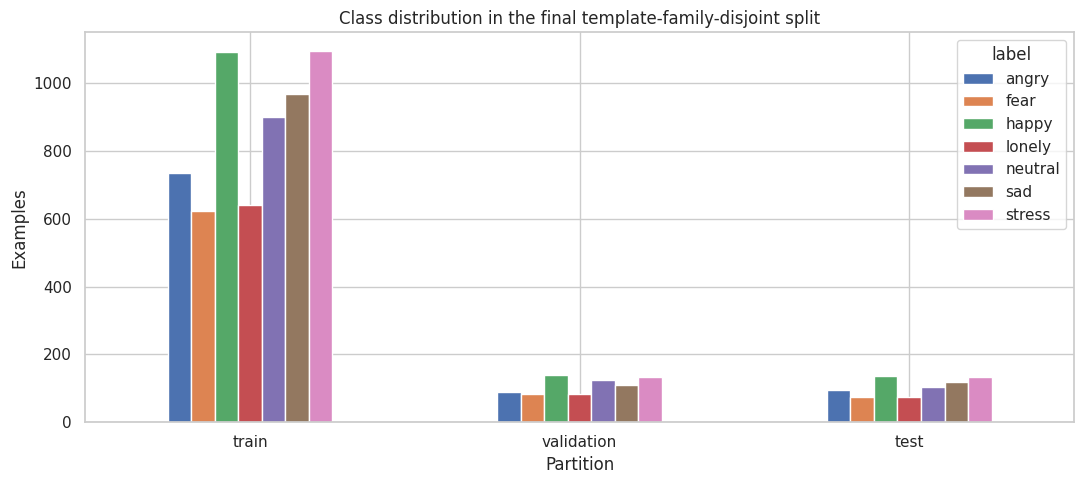

In [12]:
if len(sample) != EXPECTED_ROWS:
    warnings.warn(f"The benchmark has {len(sample):,} rows; the original experiment had {EXPECTED_ROWS:,}. "
                  "Continuing, but the numbers will not be directly comparable with earlier runs.")
assert sample["text_key"].is_unique
assert set(sample["label"]) == set(LABELS)

print("Final benchmark rows:", len(sample))
display(sample["label"].value_counts().reindex(LABELS).rename("rows").to_frame())
display(
    sample.groupby("label", group_keys=False)
    .sample(n=2, random_state=CFG.seed)[["text", "label"]]
)

DIRECT_CUES = {
    "angry": ["ខឹង", "កំហឹង", "ក្រហាយ"],
    "fear": ["ភ័យខ្លាច", "ខ្លាច", "ភ័យ"],
    "happy": ["សប្បាយចិត្ត", "រីករាយ", "ស្រស់ស្រាយ"],
    "lonely": ["ម្នាក់ឯង", "ឯកោ", "ឯកា"],
    "neutral": ["ស្ងប់ស្ងាត់", "ធម្មតា"],
    "sad": ["សោកសៅ", "ខូចចិត្ត", "ទឹកភ្នែក"],
    "stress": ["សម្ពាធ", "តានតឹង", "ស្ត្រេស", "ថប់"],
}
ALL_DIRECT_CUES = sorted(
    {cue for cues in DIRECT_CUES.values() for cue in cues},
    key=len,
    reverse=True,
)
GROUP_MASK = "[អារម្មណ៍]"

def mask_for_template_discovery(text):
    masked = text
    for cue in ALL_DIRECT_CUES:
        masked = masked.replace(cue, GROUP_MASK)
    return masked

sample["grouping_text"] = sample["text"].map(mask_for_template_discovery)
sample["cue_was_masked"] = sample["grouping_text"].ne(sample["text"])
mask_audit = (
    sample.groupby("label")["cue_was_masked"]
    .agg(masked_rows="sum", total_rows="count", masked_fraction="mean")
    .reindex(LABELS)
)
display(mask_audit)

template_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_df=0.995,
    max_features=250_000,
    sublinear_tf=True,
    dtype=np.float32,
)
template_vectors = template_vectorizer.fit_transform(sample["grouping_text"])
neighbor_count = min(CFG.template_neighbors, len(sample))
template_neighbors = NearestNeighbors(
    n_neighbors=neighbor_count,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1,
).fit(template_vectors)
template_distances, template_indices = template_neighbors.kneighbors(template_vectors)

edge_rows, edge_columns = [], []
for row_index in range(len(sample)):
    for distance, neighbor_index in zip(
        template_distances[row_index, 1:], template_indices[row_index, 1:]
    ):
        similarity = 1.0 - float(distance)
        if similarity >= CFG.template_similarity:
            edge_rows.extend([row_index, int(neighbor_index)])
            edge_columns.extend([int(neighbor_index), row_index])

template_graph = coo_matrix(
    (np.ones(len(edge_rows), dtype=np.uint8), (edge_rows, edge_columns)),
    shape=(len(sample), len(sample)),
).tocsr()
template_group_count, template_groups = connected_components(
    template_graph, directed=False
)
sample["template_group"] = template_groups

template_audit = (
    sample.groupby("template_group")
    .agg(size=("text_key", "size"), labels=("label", "nunique"))
    .sort_values("size", ascending=False)
)
print("Stronger template families:", template_group_count)
print(
    "Rows in non-singleton families:",
    int(template_audit.loc[template_audit["size"] > 1, "size"].sum()),
)
print("Largest stronger family:", int(template_audit["size"].max()))
print("Families containing multiple labels:", int(template_audit["labels"].gt(1).sum()))
display(template_audit.head(20))

fold_assignment = np.full(len(sample), -1, dtype=int)
fold_builder = StratifiedGroupKFold(
    n_splits=10, shuffle=True, random_state=CFG.seed
)
for fold_number, (_, fold_indices) in enumerate(
    fold_builder.split(
        sample["grouping_text"],
        sample["label"],
        groups=sample["template_group"],
    )
):
    fold_assignment[fold_indices] = fold_number

assert (fold_assignment >= 0).all()
sample["split"] = np.where(
    fold_assignment == 0,
    "test",
    np.where(fold_assignment == 1, "validation", "train"),
)

assert sample.groupby("template_group")["split"].nunique().max() == 1
split_groups = {
    name: set(sample.loc[sample["split"] == name, "template_group"])
    for name in ["train", "validation", "test"]
}
assert split_groups["train"].isdisjoint(split_groups["validation"])
assert split_groups["train"].isdisjoint(split_groups["test"])
assert split_groups["validation"].isdisjoint(split_groups["test"])

split_table = pd.crosstab(sample["split"], sample["label"]).reindex(
    index=["train", "validation", "test"], columns=LABELS, fill_value=0
)
display(split_table)
print("Split totals:", split_table.sum(axis=1).to_dict())
print("Verified: no stronger template family crosses partitions.")

split_columns = [
    "text_key", "text", "label", "near_duplicate_group",
    "template_group", "split", "source_id", "source_file",
    "original_copies", "suffix_copies",
]
sample[split_columns].to_parquet(
    PREP_OUT / "final_template_group_split.parquet", index=False
)
mask_audit.to_csv(PREP_OUT / "template_mask_audit.csv")
template_audit.to_csv(PREP_OUT / "template_family_audit.csv")

split_table.plot.bar(figsize=(11, 5))
plt.title("Class distribution in the final template-family-disjoint split")
plt.xlabel("Partition")
plt.ylabel("Examples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(PREP_OUT / "final_split_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

### P7. Split validation

The final checks cover unique text keys, required labels, expected partitions, and group separation. A split fingerprint is saved so this exact benchmark can be identified in later runs.

In [13]:
data = sample[split_columns].copy().reset_index(drop=True)

required_columns = {"text_key", "text", "label", "template_group", "split"}
missing_columns = required_columns - set(data.columns)
if missing_columns:
    raise ValueError(f"Frozen split is missing columns: {sorted(missing_columns)}")

print(f"Rows: {len(data):,}" + ("  (same as the original experiment)" if len(data) == EXPECTED_ROWS else f"  (the original experiment had {EXPECTED_ROWS:,})"))
assert data["text_key"].is_unique
assert data["text"].notna().all()
assert set(data["label"]) == set(LABELS)
assert set(data["split"]) == {"train", "validation", "test"}
assert data.groupby("template_group")["split"].nunique().max() == 1   # enforce family-disjoint partitions

groups_by_split = {s: set(data.loc[data["split"] == s, "template_group"]) for s in ["train", "validation", "test"]}
assert groups_by_split["train"].isdisjoint(groups_by_split["validation"])
assert groups_by_split["train"].isdisjoint(groups_by_split["test"])
assert groups_by_split["validation"].isdisjoint(groups_by_split["test"])

split_table = pd.crosstab(data["split"], data["label"]).reindex(
    index=["train", "validation", "test"], columns=LABELS, fill_value=0)
split_table["total"] = split_table.sum(axis=1)
display(split_table)
print("Template families:", data["template_group"].nunique(), "| verified: no family crosses a partition.")

split_fingerprint = hashlib.sha256(
    "|".join(data.sort_values("text_key")[["text_key", "label", "split", "template_group"]]
             .astype(str).agg("::".join, axis=1)).encode("utf-8")).hexdigest()
print("Frozen split fingerprint:", split_fingerprint)
if split_fingerprint == EXPECTED_FINGERPRINT:
    print("OK: this is exactly the same data as the original experiment.")
else:
    print("NOTE: the fingerprint differs from the original run, so the split is not identical to the one used earlier. "
          "The usual cause is a different scikit-learn version (the original used 1.6.1; see the setup cell). "
          "Results are valid for THIS split but are not directly comparable sentence-by-sentence with earlier runs.")

print("\nTwo example sentences per emotion:")
display(data.groupby("label", group_keys=False).sample(n=2, random_state=CFG.seed)[["label", "text", "split"]])

Rows: 7,558  (same as the original experiment)


label,angry,fear,happy,lonely,neutral,sad,stress,total
split,,,,,,,,
train,735,624,1092,642,900,968,1096,6057
validation,90,83,138,84,124,111,135,765
test,94,75,136,75,103,118,135,736


Template families: 6424 | verified: no family crosses a partition.
Frozen split fingerprint: 153b49c5ba58b2dd10c9e754eeaf63ae5c054b9011208523e1d88b62c4a4db34
OK: this is exactly the same data as the original experiment.

Two example sentences per emotion:


,label,text,split
72,angry,ចិត្តរបស់ខ្ញុំកំពុងតែឆេះក្ដៅ ព្រោះតែភាពអយុត្តិ...,train
120,angry,គាត់ គឺធ្វើការងារក្រុមតែមានអ្នកអត់ទទួលខុសត្រូវ...,train
1456,fear,ខ្ញុំមានអារម្មណ៍ភ័យខ្លាចនិងបារម្ភជាខ្លាំង ដោយស...,train
1034,fear,ភាពភ័យខ្លាចបានធ្វើឱ្យខ្ញុំមានអារម្មណ៍មិនសុវត្ថ...,validation
2907,happy,ក្នុងរយៈពេលប៉ុន្មានថ្ងៃចុងក្រោយនេះ ខ្ញុំដឹងគុណ...,train
1957,happy,ញញឹមពេញមួយថ្ងៃតែម្តងថ្ងៃនេះ ហត់នឿយណាស់ ❤️,train
3144,lonely,ខ្ញុំមានអារម្មណ៍ថាខ្លួនឯងដូចជាមនុស្សម្នាក់ដែលត...,train
3216,lonely,គេ ពិតជាគ្មានអ្នកណាម្នាក់ចាំស្តាប់ឬយល់ពីអារម្ម...,train
4654,neutral,គ្មានអ្វីប្លែកទេ គ្រាន់តែសម្អាតបន្ទប់គេង ប៉ុណ្...,train
4606,neutral,រាល់សប្តាហ៍ ថ្ងៃនេះខ្ញុំសម្អាតឡានមុនចេញធ្វើដំណើរ។,validation


## 1. Dataset overview

Class counts, sentence lengths, and template-family sizes are summarized before modeling. These checks help identify remaining imbalance or obvious length differences between emotion classes.

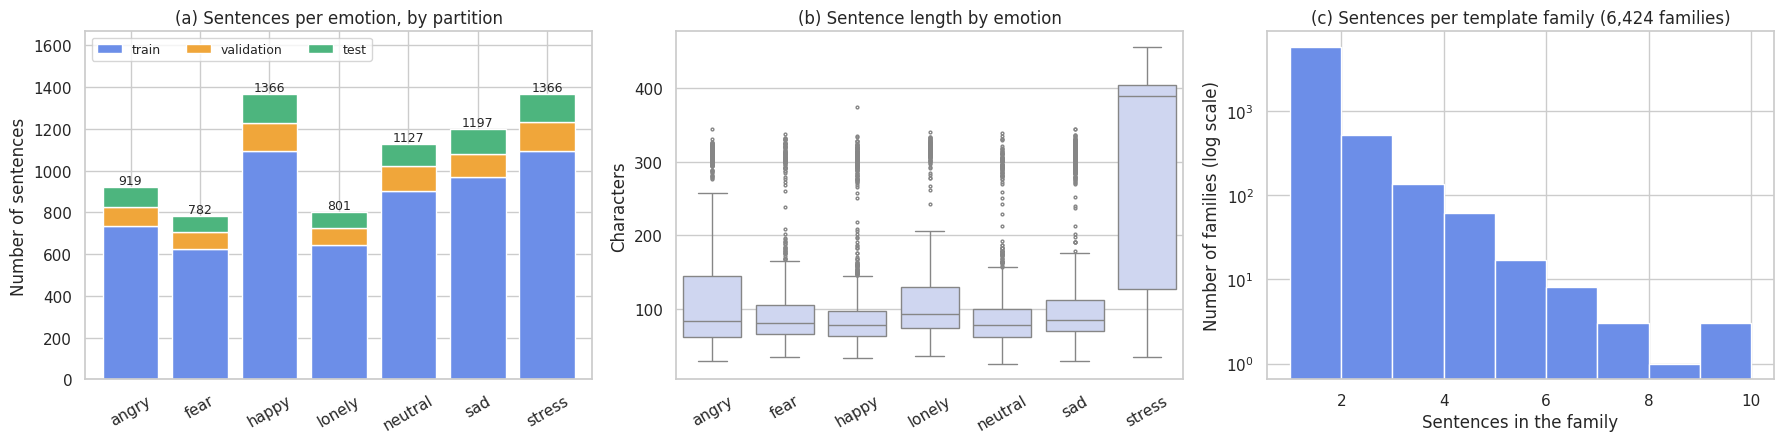

Largest class: 1366 sentences, smallest: 782. Ratio: 1.75x
Median sentence length: 89 characters. Families with more than one sentence: 749 of 6,424.


label,angry,fear,happy,lonely,neutral,sad,stress
median characters,83.0,80.0,78.0,92.0,78.0,85.0,390.0


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))

# (a) class balance per split
counts = split_table[LABELS].T[["train", "validation", "test"]]
counts.plot(kind="bar", stacked=True, ax=axes[0], color=[COLORS[c] for c in counts.columns], width=0.8)
axes[0].set_title("(a) Sentences per emotion, by partition")
axes[0].set_xlabel(""); axes[0].set_ylabel("Number of sentences"); axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, counts.sum(axis=1).max() * 1.22); axes[0].legend(ncol=3, loc="upper left", fontsize=9, title=None)
for i, label in enumerate(LABELS):
    axes[0].text(i, counts.loc[label].sum() + 15, str(int(counts.loc[label].sum())), ha="center", fontsize=9)

# (b) sentence length in characters
data["n_chars"] = data["text"].str.len()
sns.boxplot(data=data, x="label", y="n_chars", order=LABELS, ax=axes[1], color="#C9D3F5", fliersize=2)
axes[1].set_title("(b) Sentence length by emotion")
axes[1].set_xlabel(""); axes[1].set_ylabel("Characters"); axes[1].tick_params(axis="x", rotation=30)

# (c) template family sizes
family_sizes = data.groupby("template_group").size()
axes[2].hist(family_sizes, bins=range(1, int(family_sizes.max()) + 2), color="#6C8EE8", edgecolor="white")
axes[2].set_yscale("log")
axes[2].set_title(f"(c) Sentences per template family ({len(family_sizes):,} families)")
axes[2].set_xlabel("Sentences in the family"); axes[2].set_ylabel("Number of families (log scale)")

plt.tight_layout()
fig.savefig(OUT_DIR / "fig_01_data_overview.png", dpi=180, bbox_inches="tight")
plt.show()

class_totals = counts.sum(axis=1)
print(f"Largest class: {class_totals.max()} sentences, smallest: {class_totals.min()}. Ratio: {class_totals.max() / class_totals.min():.2f}x")
print(f"Median sentence length: {int(data['n_chars'].median())} characters. "
      f"Families with more than one sentence: {(family_sizes > 1).sum():,} of {len(family_sizes):,}.")

median_chars = data.groupby("label")["n_chars"].median().reindex(LABELS)
display(median_chars.rename("median characters").to_frame().T)
typical = median_chars.median()
for label, value in median_chars.items():
    if value > 1.8 * typical or value < typical / 1.8:
        print(f"WARNING: '{label}' sentences are {value / typical:.1f}x the typical length ({int(value)} vs {int(typical)} characters). "
              "Length alone hints at this emotion, so a model can score points without reading the words. Keep this in mind when interpreting results.")

### 1.1 Preprocessing record

The audit counts are combined into a single view of the corpus at four stages: raw, exact-unique, near-unique, and retained for modeling.

,stage,sentences,kept_vs_previous
0,Raw corpus,4185090,
1,After cleaning + exact de-duplication,287284,6.9%
2,After near-duplicate removal,8898,3.1%
3,Kept for modelling (after class capping),7558,84.9%


,exact_unique,near_unique,retained_for_modeling,removed_near_duplicate,removed_for_balance
label,,,,,
angry,9578,919,919,8659,0
fear,9386,782,782,8604,0
happy,10152,1366,1366,8786,0
lonely,9438,801,801,8637,0
neutral,14454,1127,1127,13327,0
sad,9791,1197,1197,8594,0
stress,224485,2706,1366,221779,1340


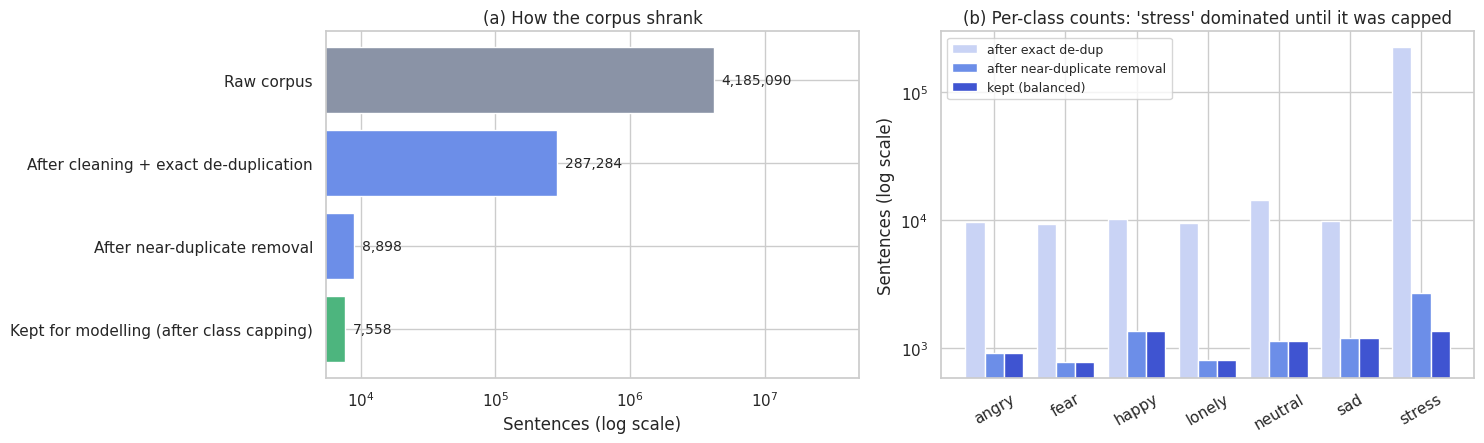

In [15]:
balance = balance_audit
funnel = pd.DataFrame({
    "stage": ["Raw corpus", "After cleaning + exact de-duplication", "After near-duplicate removal", "Kept for modelling (after class capping)"],
    "sentences": [audit["raw_rows"], audit["eligible_unique_texts"], int(balance["near_unique"].sum()), int(balance["retained_for_modeling"].sum())],
})
funnel["kept_vs_previous"] = (funnel["sentences"] / funnel["sentences"].shift(1)).map(lambda v: "" if pd.isna(v) else f"{v:.1%}")
display(funnel)
display(balance)
assert int(balance["retained_for_modeling"].sum()) == len(data), "audit and split disagree on the number of sentences"

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].barh(funnel["stage"][::-1], funnel["sentences"][::-1], color=["#4DB57E", "#6C8EE8", "#6C8EE8", "#8A93A6"])
axes[0].set_xscale("log"); axes[0].set_xlabel("Sentences (log scale)")
axes[0].set_title("(a) How the corpus shrank")
for y, v in enumerate(funnel["sentences"][::-1]):
    axes[0].text(v * 1.15, y, f"{v:,}", va="center", fontsize=10)
axes[0].set_xlim(right=funnel["sentences"].max() * 12)

x = np.arange(len(LABELS)); w = 0.27
axes[1].bar(x - w, balance["exact_unique"], w, label="after exact de-dup", color="#C9D3F5")
axes[1].bar(x, balance["near_unique"], w, label="after near-duplicate removal", color="#6C8EE8")
axes[1].bar(x + w, balance["retained_for_modeling"], w, label="kept (balanced)", color="#3F54D1")
axes[1].set_yscale("log"); axes[1].set_xticks(x); axes[1].set_xticklabels(LABELS, rotation=30)
axes[1].set_title("(b) Per-class counts: 'stress' dominated until it was capped"); axes[1].set_ylabel("Sentences (log scale)")
axes[1].legend(fontsize=9)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig_02_preprocessing_funnel.png", dpi=180, bbox_inches="tight")
plt.show()

### 1.2 Model-ready partitions

The frozen split is separated into train, validation, and test tables. Labels are mapped to integer IDs using the same fixed order for both models.

In [16]:
parts = {name: data.loc[data["split"] == name].copy().reset_index(drop=True) for name in ["train", "validation", "test"]}

for frame in parts.values():
    frame["label_id"] = frame["label"].map(label2id).astype(int)

y_train, y_val, y_test = (parts[n]["label_id"].to_numpy() for n in ["train", "validation", "test"])
print({name: len(frame) for name, frame in parts.items()})

{'train': 6057, 'validation': 765, 'test': 736}


## 2. Evaluation

Accuracy and macro-F1 are calculated with the same functions throughout the notebook. Uncertainty is estimated by resampling complete template families rather than individual sentences, since sentences from one family are not independent. The paired version measures the macro-F1 difference between the two models on identical resamples.

In [17]:
def metrics_from_ids(true_ids, predicted_ids):
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        true_ids, predicted_ids, labels=LABEL_IDS, average="macro", zero_division=0)
    return {
        "accuracy": accuracy_score(true_ids, predicted_ids),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": macro_f1,
        "f1_weighted": f1_score(true_ids, predicted_ids, labels=LABEL_IDS, average="weighted", zero_division=0),
    }

def macro_f1(true_ids, predicted_ids):
    return f1_score(true_ids, predicted_ids, labels=LABEL_IDS, average="macro", zero_division=0)

def _family_positions(groups):
    groups = np.asarray(groups)
    unique_groups = pd.unique(groups)
    return unique_groups, {g: np.flatnonzero(groups == g) for g in unique_groups}

def grouped_bootstrap_macro_f1(groups, true_ids, predicted_ids, repeats, seed):
    """95% interval for macro-F1, re-drawing whole template families."""
    rng = np.random.default_rng(seed)
    unique_groups, positions_by_group = _family_positions(groups)
    values = []
    for _ in tqdm(range(repeats), desc="bootstrap", leave=False):
        sampled = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        positions = np.concatenate([positions_by_group[g] for g in sampled])
        values.append(macro_f1(true_ids[positions], predicted_ids[positions]))
    return np.percentile(values, [2.5, 50, 97.5])

def paired_bootstrap_difference(groups, true_ids, predicted_a, predicted_b, repeats, seed):
    """95% interval for macro-F1(A) - macro-F1(B) on the SAME re-drawn families."""
    rng = np.random.default_rng(seed)
    unique_groups, positions_by_group = _family_positions(groups)
    diffs = []
    for _ in tqdm(range(repeats), desc="paired bootstrap", leave=False):
        sampled = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        positions = np.concatenate([positions_by_group[g] for g in sampled])
        diffs.append(macro_f1(true_ids[positions], predicted_a[positions]) - macro_f1(true_ids[positions], predicted_b[positions]))
    return np.percentile(diffs, [2.5, 50, 97.5])

def per_class_report(true_ids, predicted_ids):
    return pd.DataFrame(classification_report(
        true_ids, predicted_ids, labels=LABEL_IDS, target_names=LABELS, output_dict=True, zero_division=0)).T

def plot_confusion(true_ids, predicted_ids, title, ax):
    """Row-normalised: each row shows where the sentences of one TRUE emotion ended up."""
    matrix = confusion_matrix(true_ids, predicted_ids, labels=LABEL_IDS, normalize="true")
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS,
                vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")

def confidence_plot(frame, title, ax, color_ok=COLORS["xlmr"]):
    """How sure was the model when it was right versus when it was wrong?"""
    bins = np.linspace(0, 1, 21)
    ax.hist(frame.loc[frame["correct"], "confidence"], bins=bins, alpha=0.85, color=color_ok, label=f"correct ({int(frame['correct'].sum())})")
    if (~frame["correct"]).any():
        ax.hist(frame.loc[~frame["correct"], "confidence"], bins=bins, alpha=0.9, color=COLORS["wrong"], label=f"wrong ({int((~frame['correct']).sum())})")
    ax.set_yscale("log"); ax.set_xlabel("Confidence in its own prediction"); ax.set_ylabel("Sentences (log scale)")
    ax.set_title(title); ax.legend()

print("Helpers ready.")

Helpers ready.


## 3. TF-IDF and Logistic Regression baseline

Khmer sentences are segmented with `khmer-nltk` and represented by TF-IDF word unigrams and bigrams. Logistic Regression is trained on the training partition, with `C` selected by validation macro-F1. The held-out test partition is not used during fitting or selection.

segmenting train:   0%|          | 0/6057 [00:00<?, ?it/s]

| 2026-11-26 03:01:42,209 | INFO | khmer-nltk | Loaded model from /usr/local/lib/python3.13/dist-packages/khmernltk/word_tokenize/sklearn_crf_ner_10000.sav |
INFO:khmer-nltk:Loaded model from /usr/local/lib/python3.13/dist-packages/khmernltk/word_tokenize/sklearn_crf_ner_10000.sav


segmenting validation:   0%|          | 0/765 [00:00<?, ?it/s]

segmenting test:   0%|          | 0/736 [00:00<?, ?it/s]

Word segmentation of all sentences took 30 seconds.

original : ហេតុអ្វីបានជាចូលចិត្តមកបៀតបៀនជីវិតអ្នកដទៃម្ល៉េះ? ខ្លាំងមែនទែន 😱
segmented: ហេតុ អ្វី បានជា ចូលចិត្ត មក បៀតបៀន ជីវិត អ្នកដទៃ ម្ល៉េះ ? ខ្លាំង មែនទែន 😱 

original : ខ្ញុំមិនអាចអត់ធ្មត់ចំពោះការត្រូវគេធ្វើអយុត្តិធម៌នៅកន្លែងធ្វើការបានទេ វាធ្វើឱ្យខ្ញុំមិនអាចទប់អារម្មណ៍បាន។
segmented: ខ្ញុំ មិន អាច អត់ធ្មត់ ចំពោះ ការត្រូវ គេ ធ្វើអយុត្តិធម៌ នៅ កន្លែង ធ្វើការ បាន ទេ វា ធ្វើឱ្យ ខ្ញុំ មិន អាច ទប់ អារម្មណ៍ បាន ។ 

Feature matrix: 6,057 training sentences x 8,810 word / word-pair features


trying C values:   0%|          | 0/5 [00:00<?, ?it/s]

,C,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,0.1,0.9673,0.9697,0.9624,0.9656,0.9670
1,1.0,0.9935,0.9930,0.9929,0.9930,0.9935
2,10.0,0.9948,0.9947,0.9942,0.9945,0.9948
3,100.0,0.9948,0.9941,0.9942,0.9941,0.9948
4,1000.0,0.9935,0.9929,0.9932,0.9931,0.9935


Chosen C = 10.0 (highest VALIDATION macro-F1). Segmentation + training + tuning took 41 seconds.


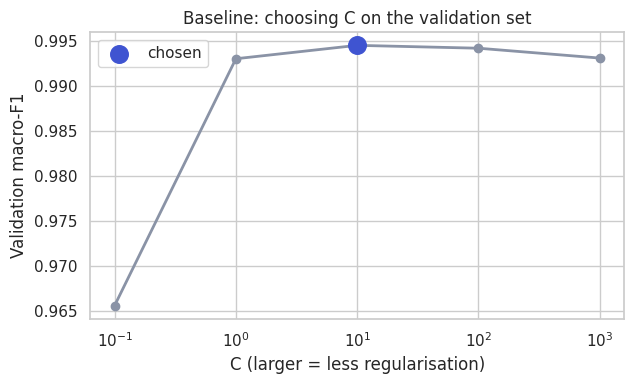

In [18]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def segment_khmer(text):
    """Segment Khmer text into words joined by single spaces (blank tokens dropped)."""
    return " ".join(word for word in khmer_word_tokenize(text) if word.strip())

seg_started = time.perf_counter()
for name, frame in parts.items():
    frame["words"] = [segment_khmer(t) for t in tqdm(frame["text"], desc=f"segmenting {name}")]
seg_seconds = time.perf_counter() - seg_started
print(f"Word segmentation of all sentences took {seg_seconds:.0f} seconds.\n")
for _, row in parts["train"].head(2).iterrows():
    print("original :", row["text"])
    print("segmented:", row["words"], "\n")

vectorizer = TfidfVectorizer(analyzer="word", tokenizer=str.split, token_pattern=None, lowercase=False,
                             ngram_range=CFG.word_ngram_range, min_df=2, sublinear_tf=True, max_features=CFG.max_features)
X_train = vectorizer.fit_transform(parts["train"]["words"])           # fit on training data only
X_val = vectorizer.transform(parts["validation"]["words"])
X_test = vectorizer.transform(parts["test"]["words"])
print(f"Feature matrix: {X_train.shape[0]:,} training sentences x {X_train.shape[1]:,} word / word-pair features")

tuning_rows, fitted = [], {}
base_started = time.perf_counter()
for C in tqdm(CFG.c_grid, desc="trying C values"):
    model_c = LogisticRegression(C=C, max_iter=3000, random_state=CFG.seed).fit(X_train, y_train)
    fitted[C] = model_c
    tuning_rows.append({"C": C, **metrics_from_ids(y_val, model_c.predict(X_val))})
baseline_minutes = (time.perf_counter() - base_started + seg_seconds) / 60

tuning = pd.DataFrame(tuning_rows)
BEST_C = float(tuning.loc[tuning["f1_macro"].idxmax(), "C"])
baseline_model = fitted[BEST_C]
display(tuning.round(4))
print(f"Chosen C = {BEST_C} (highest VALIDATION macro-F1). Segmentation + training + tuning took {baseline_minutes*60:.0f} seconds.")
if BEST_C in (min(CFG.c_grid), max(CFG.c_grid)):
    print("Note: the best C sits at the edge of the grid; a wider grid might help slightly.")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tuning["C"], tuning["f1_macro"], marker="o", color=COLORS["baseline"], lw=2)
ax.scatter([BEST_C], [tuning.loc[tuning["C"] == BEST_C, "f1_macro"].iloc[0]], s=160, color=COLORS["xlmr"], zorder=5, label="chosen")
ax.set_xscale("log"); ax.set_xlabel("C (larger = less regularisation)"); ax.set_ylabel("Validation macro-F1")
ax.set_title("Baseline: choosing C on the validation set"); ax.legend()
plt.tight_layout(); fig.savefig(BASE_OUT / "fig_03_baseline_tuning.png", dpi=180, bbox_inches="tight"); plt.show()

### 3.1 Held-out evaluation

The selected baseline is scored on the test partition using accuracy, macro-F1, per-class metrics, a group-bootstrap interval, and a confusion matrix.

bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Baseline (TF-IDF + LR),0.9891,0.9887,0.9901,0.9893,0.9891


Macro-F1 95% interval (re-drawing template families): [0.9789, 0.9972]  median 0.9897


,precision,recall,f1-score,support
angry,1.000,1.000,1.000,94.000
fear,1.000,1.000,1.000,75.000
happy,0.993,0.978,0.985,136.000
lonely,0.974,0.987,0.980,75.000
neutral,0.971,0.990,0.981,103.000
sad,0.983,0.983,0.983,118.000
stress,1.000,0.993,0.996,135.000
accuracy,0.989,0.989,0.989,0.989
macro avg,0.989,0.990,0.989,736.000
weighted avg,0.989,0.989,0.989,736.000


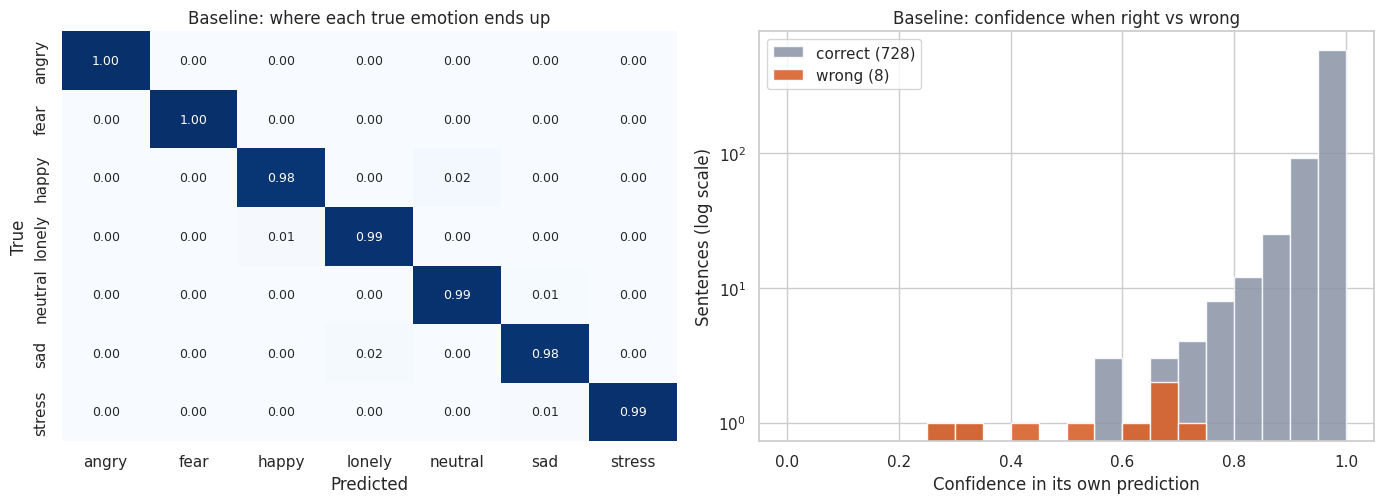

In [19]:
base_test_probs = baseline_model.predict_proba(X_test)
base_test_pred = base_test_probs.argmax(axis=1)
base_metrics = metrics_from_ids(y_test, base_test_pred)
base_interval = grouped_bootstrap_macro_f1(parts["test"]["template_group"], y_test, base_test_pred, CFG.bootstrap_repeats, CFG.seed)

display(pd.DataFrame([{"model": "Baseline (TF-IDF + LR)", **base_metrics}]).round(4))
print("Macro-F1 95% interval (re-drawing template families): "
      f"[{base_interval[0]:.4f}, {base_interval[2]:.4f}]  median {base_interval[1]:.4f}")

base_report = per_class_report(y_test, base_test_pred)
display(base_report.round(3))

base_results = parts["test"][["text_key", "text", "label", "template_group"]].copy()
base_results["prediction"] = [id2label[i] for i in base_test_pred]
base_results["correct"] = base_results["label"].eq(base_results["prediction"])
base_results["confidence"] = base_test_probs.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plot_confusion(y_test, base_test_pred, "Baseline: where each true emotion ends up", axes[0])
confidence_plot(base_results, "Baseline: confidence when right vs wrong", axes[1], color_ok=COLORS["baseline"])
plt.tight_layout(); fig.savefig(BASE_OUT / "fig_04_baseline_test.png", dpi=180, bbox_inches="tight"); plt.show()

### 3.2 Learned features

For each emotion, the largest positive classifier weights show which Khmer words or word pairs contribute most to that prediction.

In [20]:
feature_names = np.asarray(vectorizer.get_feature_names_out())
top_words = pd.DataFrame({
    label: [feature_names[i] for i in np.argsort(baseline_model.coef_[k])[-8:][::-1]]
    for k, label in enumerate(LABELS)
}).T
top_words.columns = [f"#{i}" for i in range(1, 9)]
display(top_words)

,#1,#2,#3,#4,#5,#6,#7,#8
angry,ខឹង,គេ,ខឹង ខ្លាំង,ក្តៅក្រហាយ,មក,ខ្ញុំ ខឹង,ទង្វើ,និយាយ
fear,ខ្លាច,ភ័យខ្លាច,ភ័យ,ហ៊ាន,មិន ហ៊ាន,ភ័យខ្លាច ខ្លាំង,ខ្លាចក្រែង,ញ័រ
happy,ទទួលបាន,សប្បាយ,ញញឹម,ស្រស់ស្រាយ,រំភើបចិត្ត,មាន កម្លាំងចិត្ត,បាន,ពិតជា មាន
lonely,ម្នាក់ឯង,ឯកោ,ឯកា,ម្នាក់,ឯកោ ខ្លាំង,អារម្មណ៍ ឯកោ,ចង់ មាន,ឆ្ងាយ
neutral,ធម្មតា,ថ្ងៃ,នេះ ខ្ញុំ,តាម,ថ្ងៃ នេះ,ស្ងប់ស្ងាត់,គឺ,ដូច
sad,ទឹកភ្នែក,ឈឺចាប់,យំ,ការបាត់បង់,ចង់ នៅ,ខូចចិត្ត,សោក សៅ,សោក
stress,តានតឹង,និង,សម្ពាធ,ពេក,ថប់,ស្ត្រេស,ចាប់តាំងពី មាន,ធ្វើឱ្យ


### 3.3 Alternative TF-IDF features

Word unigrams and character n-grams are fitted as additional baselines using the same partitions and validation procedure. This keeps the comparison focused on the feature representation.

,tokenisation,features,best_C,val_macro_f1,test_accuracy,test_f1_macro
0,"Words, unigrams + bigrams (our baseline)",8810,10.0,0.9945,0.9891,0.9893
1,"Words, unigrams only",1422,10.0,0.9916,0.9905,0.9903
2,"Characters, 2-5-grams (no segmenter)",49136,1000.0,0.9927,0.9905,0.9904


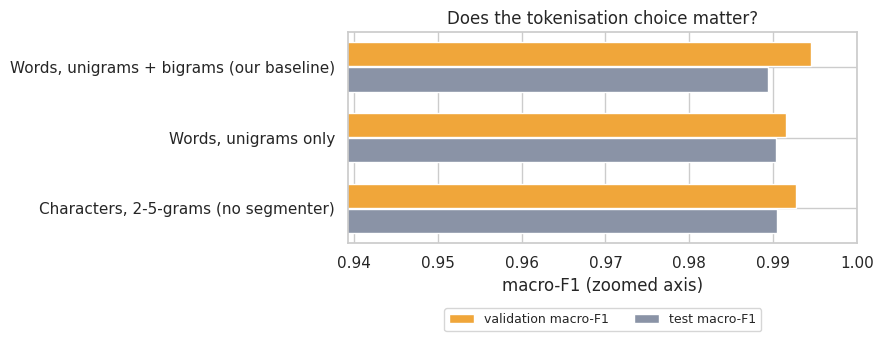

Baseline saved in: /content/khmer_work/results/baseline


In [21]:
def fit_and_score(vec, train_text, val_text, test_text):
    """Same recipe as the main baseline: fit on train, pick C on validation, report validation and test."""
    Xtr = vec.fit_transform(train_text); Xva, Xte = vec.transform(val_text), vec.transform(test_text)
    best = None
    for C in CFG.c_grid:
        m = LogisticRegression(C=C, max_iter=3000, random_state=CFG.seed).fit(Xtr, y_train)
        f = macro_f1(y_val, m.predict(Xva))
        if best is None or f > best[0]:
            best = (f, C, m)
    f, C, m = best
    pred = m.predict(Xte)
    return {"features": Xtr.shape[1], "best_C": C, "val_macro_f1": f,
            "test_accuracy": accuracy_score(y_test, pred), "test_f1_macro": macro_f1(y_test, pred)}

base_pred_preview = baseline_model.predict(X_test)
rows = [{"tokenisation": "Words, unigrams + bigrams (our baseline)", "features": X_train.shape[1], "best_C": BEST_C,
         "val_macro_f1": float(tuning.loc[tuning["C"] == BEST_C, "f1_macro"].iloc[0]),
         "test_accuracy": accuracy_score(y_test, base_pred_preview), "test_f1_macro": macro_f1(y_test, base_pred_preview)}]

alternatives = {
    "Words, unigrams only": (TfidfVectorizer(analyzer="word", tokenizer=str.split, token_pattern=None, lowercase=False,
                                             ngram_range=(1, 1), min_df=2, sublinear_tf=True), "words"),
    "Characters, 2-5-grams (no segmenter)": (TfidfVectorizer(analyzer="char", ngram_range=(2, 5), min_df=2,
                                                             sublinear_tf=True, max_features=CFG.max_features), "text"),
}
for name, (vec, column) in alternatives.items():
    rows.append({"tokenisation": name,
                 **fit_and_score(vec, parts["train"][column], parts["validation"][column], parts["test"][column])})

tokenisation_check = pd.DataFrame(rows)
display(tokenisation_check.round(4))
tokenisation_check.to_csv(BASE_OUT / "baseline_tokenisation_check.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.8))
ypos = np.arange(len(tokenisation_check))[::-1]
ax.barh(ypos + 0.18, tokenisation_check["val_macro_f1"], height=0.34, color="#F0A63A", label="validation macro-F1")
ax.barh(ypos - 0.18, tokenisation_check["test_f1_macro"], height=0.34, color=COLORS["baseline"], label="test macro-F1")
ax.set_yticks(ypos); ax.set_yticklabels(tokenisation_check["tokenisation"])
lowest = float(min(tokenisation_check["val_macro_f1"].min(), tokenisation_check["test_f1_macro"].min()))
ax.set_xlim(max(0, lowest - 0.05), 1.0); ax.set_xlabel("macro-F1 (zoomed axis)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=9); ax.set_title("Does the tokenisation choice matter?")
plt.tight_layout(); fig.savefig(BASE_OUT / "fig_03b_tokenisation_check.png", dpi=180, bbox_inches="tight"); plt.show()

base_results.to_parquet(BASE_OUT / "baseline_test_predictions.parquet", index=False)
base_report.to_csv(BASE_OUT / "baseline_classification_report.csv")
tuning.to_csv(BASE_OUT / "baseline_validation_tuning.csv", index=False)
joblib.dump({"vectorizer": vectorizer, "model": baseline_model, "labels": LABELS, "config": asdict(CFG),
             "preprocessing": "khmernltk.word_tokenize, tokens joined by single spaces"}, BASE_OUT / "baseline_tfidf_lr.joblib")
print("Baseline saved in:", BASE_OUT)

## 4. XLM-RoBERTa

### 4.1 Sequence length

We tokenize the sentences without truncation first and inspect their subword lengths. The configured limit is 144 tokens; anything longer is truncated during dataset encoding.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

token-length audit:   0%|          | 0/15 [00:00<?, ?it/s]

Token-length percentiles: {0: np.int64(9), 25: np.int64(22), 50: np.int64(28), 75: np.int64(50), 90: np.int64(111), 95: np.int64(120), 99: np.int64(129), 100: np.int64(143)}
Sentences longer than max_length=144: 0.00%


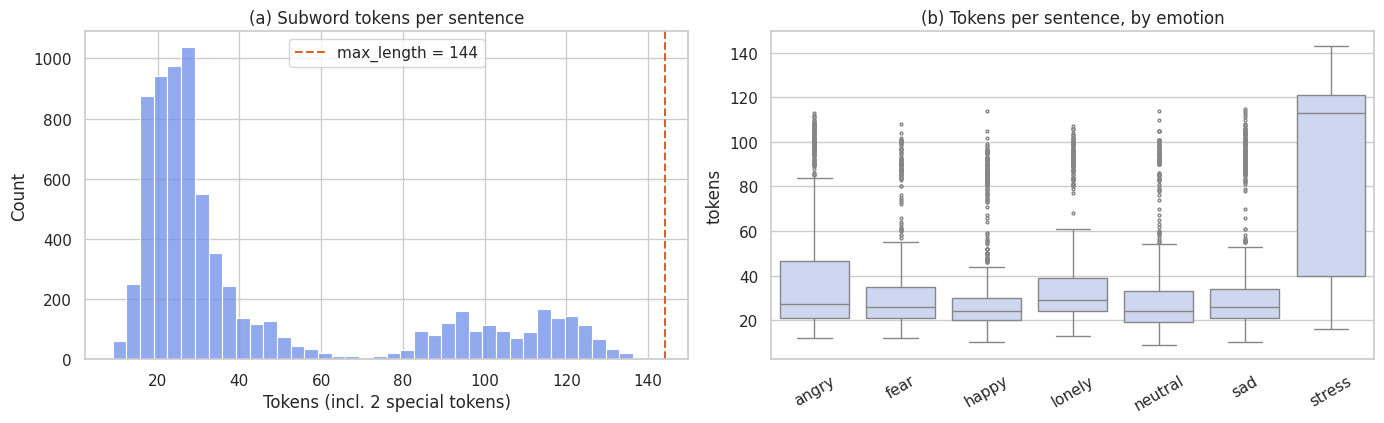


Example sentence : ហេតុអ្វីបានជាចូលចិត្តមកបៀតបៀនជីវិតអ្នកដទៃម្ល៉េះ? ខ្លាំងមែនទែន 😱
Subword pieces   : ['<s>', '▁ហេតុអ្វី', 'បាន', 'ជា', 'ចូល', 'ចិត្ត', 'មក', 'ប', 'ៀត', 'ប', 'ៀន', 'ជីវិត', 'អ្នក', 'ដ', 'ទ', 'ៃ', 'ម្', 'ល', '៉', 'េះ', '?', '▁ខ្លាំង', 'មែន', 'ទ', 'ែន', '▁', '😱', '</s>']


In [22]:
tokenizer = AutoTokenizer.from_pretrained(CFG.model_name, use_fast=True)

token_lengths = []
for start in tqdm(range(0, len(data), 512), desc="token-length audit"):
    batch = data["text"].iloc[start:start + 512].tolist()
    token_lengths.extend(len(ids) for ids in tokenizer(batch, add_special_tokens=True, truncation=False)["input_ids"])
token_lengths = np.asarray(token_lengths)

percentiles = dict(zip([0, 25, 50, 75, 90, 95, 99, 100], np.percentile(token_lengths, [0, 25, 50, 75, 90, 95, 99, 100]).round(0).astype(int)))
truncated_fraction = float(np.mean(token_lengths > CFG.max_length))
print("Token-length percentiles:", percentiles)
print(f"Sentences longer than max_length={CFG.max_length}: {truncated_fraction:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.histplot(token_lengths, bins=40, ax=axes[0], color="#6C8EE8")
axes[0].axvline(CFG.max_length, color=COLORS["wrong"], ls="--", label=f"max_length = {CFG.max_length}")
axes[0].set_title("(a) Subword tokens per sentence"); axes[0].set_xlabel("Tokens (incl. 2 special tokens)"); axes[0].legend()
length_df = pd.DataFrame({"label": data["label"].to_numpy(), "tokens": token_lengths})
sns.boxplot(data=length_df, x="label", y="tokens", order=LABELS, ax=axes[1], color="#C9D3F5", fliersize=2)
axes[1].set_title("(b) Tokens per sentence, by emotion"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); fig.savefig(XLMR_OUT / "fig_05_token_lengths.png", dpi=180, bbox_inches="tight"); plt.show()

example = data["text"].iloc[0]
print("\nExample sentence :", example)
print("Subword pieces   :", tokenizer.convert_ids_to_tokens(tokenizer(example)["input_ids"]))

### 4.2 Encoded datasets

The three partitions are converted to Hugging Face datasets and encoded with the XLM-R tokenizer. Padding is applied dynamically within each batch instead of storing every sequence at the maximum length.

In [23]:
raw_datasets = DatasetDict({
    name: Dataset.from_dict({"text": frame["text"].tolist(), "labels": frame["label_id"].tolist()})
    for name, frame in parts.items()
})

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=CFG.max_length)

encoded_datasets = raw_datasets.map(tokenize_batch, batched=True, remove_columns=["text"], desc="Tokenizing with XLM-R")
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(encoded_datasets)
print("Label mapping:", label2id)

Tokenizing with XLM-R:   0%|          | 0/6057 [00:00<?, ? examples/s]

Tokenizing with XLM-R:   0%|          | 0/765 [00:00<?, ? examples/s]

Tokenizing with XLM-R:   0%|          | 0/736 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 6057
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 765
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 736
    })
})
Label mapping: {'angry': 0, 'fear': 1, 'happy': 2, 'lonely': 3, 'neutral': 4, 'sad': 5, 'stress': 6}


### 4.3 Fine-tuning

`xlm-roberta-base` is initialized with a seven-label classification head and fine-tuned on the training partition. Validation macro-F1 selects the saved checkpoint, with early stopping after two evaluations without improvement. The seed is reset immediately before initialization, and the starting head checksum is recorded.

In [24]:
def compute_metrics(evaluation_prediction):
    predicted_ids = np.argmax(evaluation_prediction.predictions, axis=-1)
    return metrics_from_ids(evaluation_prediction.label_ids, predicted_ids)

def make_training_args(seed, output_dir):
    return TrainingArguments(
        output_dir=str(output_dir),
        overwrite_output_dir=True,
        learning_rate=CFG.learning_rate,
        per_device_train_batch_size=CFG.train_batch_size,
        per_device_eval_batch_size=CFG.eval_batch_size,
        gradient_accumulation_steps=CFG.gradient_accumulation_steps,
        num_train_epochs=CFG.epochs,
        weight_decay=CFG.weight_decay,
        warmup_ratio=CFG.warmup_ratio,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        fp16=True,
        dataloader_pin_memory=True,
        dataloader_num_workers=2,
        group_by_length=True,
        optim="adamw_torch",
        report_to="none",
        seed=seed,
        data_seed=seed,
    )

def head_checksum(m):
    """A number that identifies the random starting values of the new classification head."""
    return float(sum(p.detach().double().abs().sum() for n, p in m.named_parameters() if n.startswith("classifier.")))

torch.cuda.empty_cache()
set_seed(CFG.seed)                      # reset before classifier-head initialization
model = AutoModelForSequenceClassification.from_pretrained(
    CFG.model_name, num_labels=len(LABELS), label2id=label2id, id2label=id2label)
HEAD_CHECKSUM = head_checksum(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(f"Classification-head starting checksum (seed {CFG.seed}): {HEAD_CHECKSUM:.6f}")

training_args = make_training_args(CFG.seed, CHECKPOINT_DIR)
trainer = Trainer(
    model=model, args=training_args,
    train_dataset=encoded_datasets["train"], eval_dataset=encoded_datasets["validation"],
    processing_class=tokenizer, data_collator=data_collator, compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

training_started = time.perf_counter()
trainer.train()
training_minutes = (time.perf_counter() - training_started) / 60

xlmr_run = {"best_metric": float(trainer.state.best_metric),
            "best_checkpoint": str(trainer.state.best_model_checkpoint),
            "training_minutes": training_minutes,
            "head_checksum": HEAD_CHECKSUM,
            "log_history": trainer.state.log_history}
trainer.save_model(str(FINAL_MODEL_DIR))        # temporary local storage
tokenizer.save_pretrained(str(FINAL_MODEL_DIR))
print(f"\nTraining runtime: {training_minutes:.2f} minutes")
print("Best checkpoint         :", xlmr_run["best_checkpoint"])
print("Best validation macro-F1:", round(xlmr_run["best_metric"], 4))

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable parameters: 278,049,031
Classification-head starting checksum (seed 42): 9509.787452


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,0.234100,0.144534,0.960784,0.960743,0.959177,0.959265,0.960973
2,0.017900,0.028797,0.994771,0.993473,0.994025,0.993710,0.994766
3,0.010300,0.033650,0.994771,0.994671,0.994482,0.994519,0.994775



Training runtime: 13.14 minutes
Best checkpoint         : /content/khmer_work/xlmr_checkpoints/checkpoint-1137
Best validation macro-F1: 0.9945


### 4.4 Training curves

Training loss, validation loss, and validation macro-F1 are taken from the trainer history and plotted by epoch.

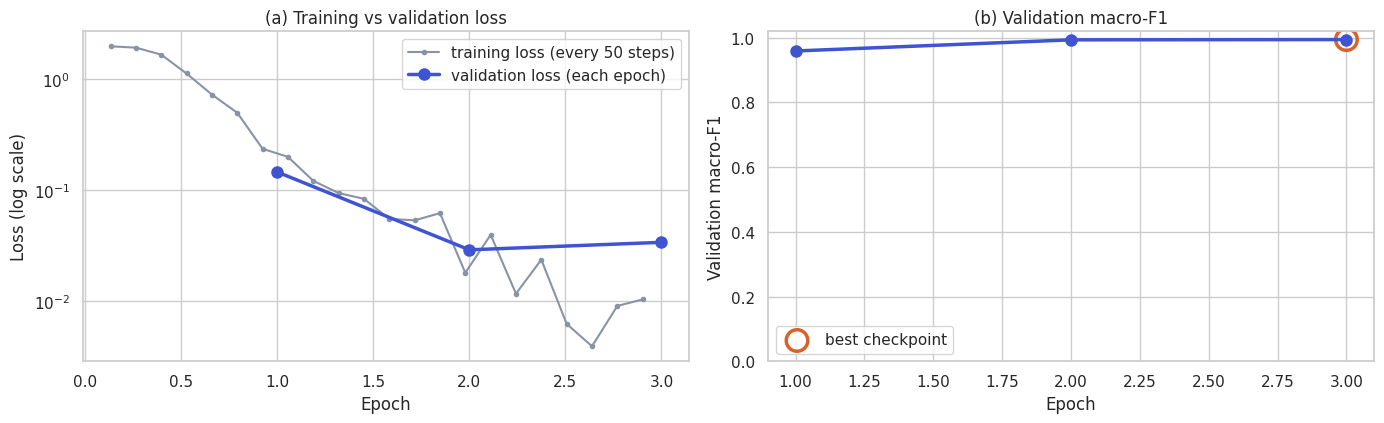

,epoch,step,eval_loss,eval_accuracy,eval_f1_macro
7,1.0,379,0.1445,0.9608,0.9593
16,2.0,758,0.0288,0.9948,0.9937
24,3.0,1137,0.0336,0.9948,0.9945


In [25]:
history = pd.DataFrame(xlmr_run["log_history"])
history.to_csv(XLMR_OUT / "xlmr_training_history.csv", index=False)
training_log = history.dropna(subset=["loss"]) if "loss" in history else pd.DataFrame()
evaluation_log = history.dropna(subset=["eval_loss"]) if "eval_loss" in history else pd.DataFrame()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
if not training_log.empty:
    axes[0].plot(training_log["epoch"], training_log["loss"], marker="o", ms=3, color="#8A93A6", label="training loss (every 50 steps)")
if not evaluation_log.empty:
    axes[0].plot(evaluation_log["epoch"], evaluation_log["eval_loss"], marker="o", ms=8, lw=2.5, color=COLORS["xlmr"], label="validation loss (each epoch)")
axes[0].set_yscale("log"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss (log scale)")
axes[0].set_title("(a) Training vs validation loss"); axes[0].legend()

if not evaluation_log.empty:
    axes[1].plot(evaluation_log["epoch"], evaluation_log["eval_f1_macro"], marker="o", ms=8, lw=2.5, color=COLORS["xlmr"])
    best_row = evaluation_log.loc[evaluation_log["eval_f1_macro"].idxmax()]
    axes[1].scatter([best_row["epoch"]], [best_row["eval_f1_macro"]], s=240, facecolors="none", edgecolors=COLORS["wrong"], lw=2.5, label="best checkpoint")
    axes[1].legend()
axes[1].set_ylim(0, 1.02); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation macro-F1")
axes[1].set_title("(b) Validation macro-F1")
plt.tight_layout(); fig.savefig(XLMR_OUT / "fig_06_training_curves.png", dpi=180, bbox_inches="tight"); plt.show()
display(evaluation_log[[c for c in ["epoch", "step", "eval_loss", "eval_accuracy", "eval_f1_macro"] if c in evaluation_log]].round(4))

### 4.5 Held-out evaluation

The saved XLM-R checkpoint is scored on the same test rows and with the same metrics used for the baseline. Predictions are generated without length-grouped batching so their order remains aligned with the test table.

bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,XLM-RoBERTa,0.9932,0.9932,0.9939,0.9934,0.9932


Macro-F1 95% interval (re-drawing template families): [0.9848, 1.0000]  median 0.9938


,precision,recall,f1-score,support
angry,0.989,1.000,0.995,94.000
fear,1.000,1.000,1.000,75.000
happy,1.000,0.978,0.989,136.000
lonely,1.000,0.987,0.993,75.000
neutral,0.963,1.000,0.981,103.000
sad,1.000,1.000,1.000,118.000
stress,1.000,0.993,0.996,135.000
accuracy,0.993,0.993,0.993,0.993
macro avg,0.993,0.994,0.993,736.000
weighted avg,0.993,0.993,0.993,736.000


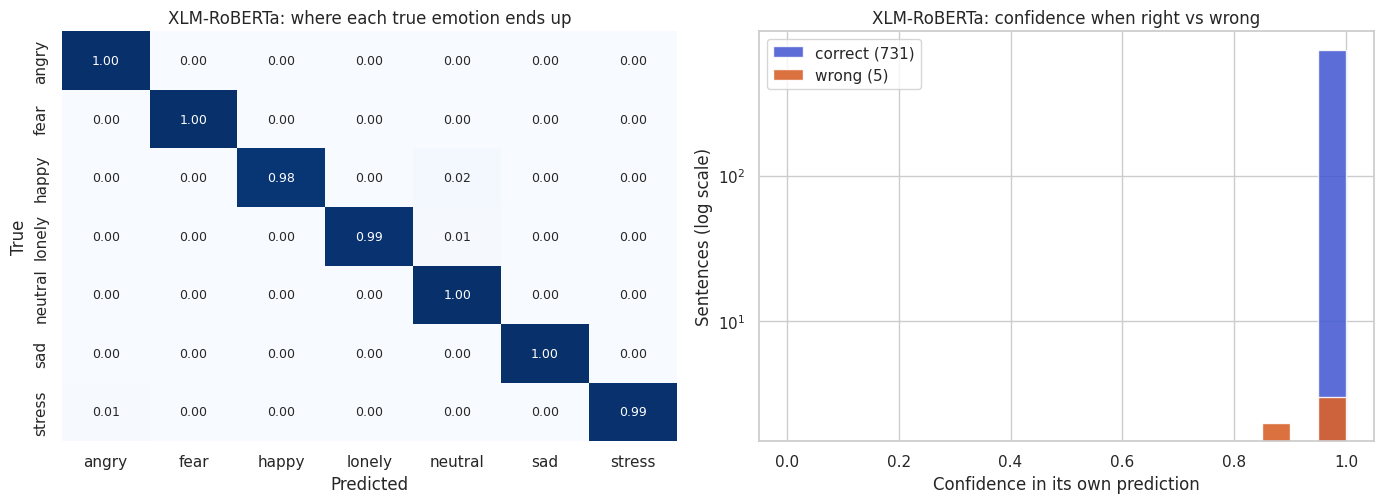

In [26]:
trainer.args.group_by_length = False          # preserve test-row order
test_output = trainer.predict(encoded_datasets["test"], metric_key_prefix="test")
trainer.args.group_by_length = True

xlmr_test_pred = np.argmax(test_output.predictions, axis=-1).astype(int)
assert np.array_equal(np.asarray(test_output.label_ids, dtype=int), y_test), "predictions are not aligned with the test rows"
xlmr_test_probs = torch.softmax(torch.tensor(test_output.predictions, dtype=torch.float32), dim=-1).numpy()

xlmr_metrics = metrics_from_ids(y_test, xlmr_test_pred)
xlmr_interval = grouped_bootstrap_macro_f1(parts["test"]["template_group"], y_test, xlmr_test_pred, CFG.bootstrap_repeats, CFG.seed)
xlmr_val_metrics = {k.replace("eval_", ""): v for k, v in trainer.evaluate(encoded_datasets["validation"]).items() if k.startswith("eval_")}

display(pd.DataFrame([{"model": "XLM-RoBERTa", **xlmr_metrics}]).round(4))
print("Macro-F1 95% interval (re-drawing template families): "
      f"[{xlmr_interval[0]:.4f}, {xlmr_interval[2]:.4f}]  median {xlmr_interval[1]:.4f}")

xlmr_report = per_class_report(y_test, xlmr_test_pred)
display(xlmr_report.round(3))

xlmr_results = parts["test"][["text_key", "text", "label", "template_group"]].copy()
xlmr_results["prediction"] = [id2label[i] for i in xlmr_test_pred]
xlmr_results["correct"] = xlmr_results["label"].eq(xlmr_results["prediction"])
xlmr_results["confidence"] = xlmr_test_probs.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plot_confusion(y_test, xlmr_test_pred, "XLM-RoBERTa: where each true emotion ends up", axes[0])
confidence_plot(xlmr_results, "XLM-RoBERTa: confidence when right vs wrong", axes[1])
plt.tight_layout(); fig.savefig(XLMR_OUT / "fig_07_xlmr_test.png", dpi=180, bbox_inches="tight"); plt.show()

### 4.6 XLM-R errors

Incorrect predictions are sorted by confidence and grouped by true-label → predicted-label pair.

XLM-R test errors: 5 of 736


,label,prediction,confidence,template_group,text
212,happy,neutral,0.998289,1880,ការងារថ្ងៃនេះរលូនល្អណាស់ គ្មានបញ្ហាអ្វីទាល់តែស...
228,happy,neutral,0.997401,1880,ការងារថ្ងៃនេះរលូនល្អណាស់ គ្មានបញ្ហាអ្វីទាល់តែសោះ។
278,happy,neutral,0.997119,1880,ការងារថ្ងៃនេះរលូនល្អណាស់ គ្មានបញ្ហាអ្វីទាល់តែស...
373,lonely,neutral,0.871051,3216,ទូរស័ព្ទរបស់ខ្ញុំស្ងាត់ច្រៀបពេញមួយថ្ងៃ គ្មានសូ...
716,stress,angry,0.856835,6230,រាល់សប្តាហ៍ ចាប់តាំងពីមានបញ្ហាលុយកាក់ខ្ញុំចាប់...


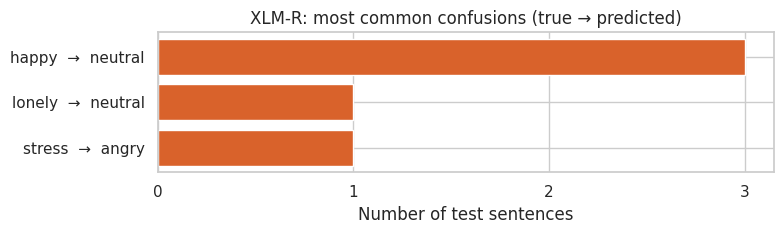

The 5 errors come from 3 template families; the biggest family accounts for 3 of them.


In [27]:
xlmr_errors = xlmr_results.loc[~xlmr_results["correct"]].sort_values("confidence", ascending=False)
print(f"XLM-R test errors: {len(xlmr_errors)} of {len(xlmr_results)}")
display(xlmr_errors[["label", "prediction", "confidence", "template_group", "text"]].head(25))

if len(xlmr_errors):
    pairs = (xlmr_errors.groupby(["label", "prediction"]).size().sort_values(ascending=False).rename("count").reset_index())
    pairs["pair"] = pairs["label"] + "  →  " + pairs["prediction"]
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.45 * len(pairs))))
    ax.barh(pairs["pair"][::-1], pairs["count"][::-1], color=COLORS["wrong"])
    ax.set_xlabel("Number of test sentences"); ax.set_title("XLM-R: most common confusions (true → predicted)")
    ax.xaxis.get_major_locator().set_params(integer=True)
    plt.tight_layout(); fig.savefig(XLMR_OUT / "fig_08_xlmr_confusion_pairs.png", dpi=180, bbox_inches="tight"); plt.show()
    same_family = xlmr_errors["template_group"].value_counts()
    print(f"The {len(xlmr_errors)} errors come from {same_family.size} template families; "
          f"the biggest family accounts for {same_family.iloc[0]} of them.")

### 4.7 Saved test files

The classification report, row-level predictions, and error table are saved under the XLM-R output directory.

In [28]:
xlmr_report.to_csv(XLMR_OUT / "xlmr_classification_report.csv")
xlmr_results.to_parquet(XLMR_OUT / "xlmr_test_predictions.parquet", index=False)
xlmr_errors.to_csv(XLMR_OUT / "xlmr_test_errors.csv", index=False)
print("Saved test predictions, report and errors in:", XLMR_OUT)

Saved test predictions, report and errors in: /content/khmer_work/results/xlmr


## 5. Model comparison

The baseline and XLM-R results are compared on the same test rows. Along with overall and per-class scores, we use a paired group bootstrap for the macro-F1 difference and place both confusion matrices side by side.

paired bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,f1_ci_low,f1_ci_high
0,Baseline (TF-IDF + LR),0.9891,0.9887,0.9901,0.9893,0.9891,0.9789,0.9972
1,XLM-RoBERTa (fine-tuned),0.9932,0.9932,0.9939,0.9934,0.9932,0.9848,1.0000


Macro-F1 difference, XLM-R minus baseline: median +0.0040, 95% interval [-0.0015, +0.0106]
-> the interval contains 0: no clear winner on this test set.


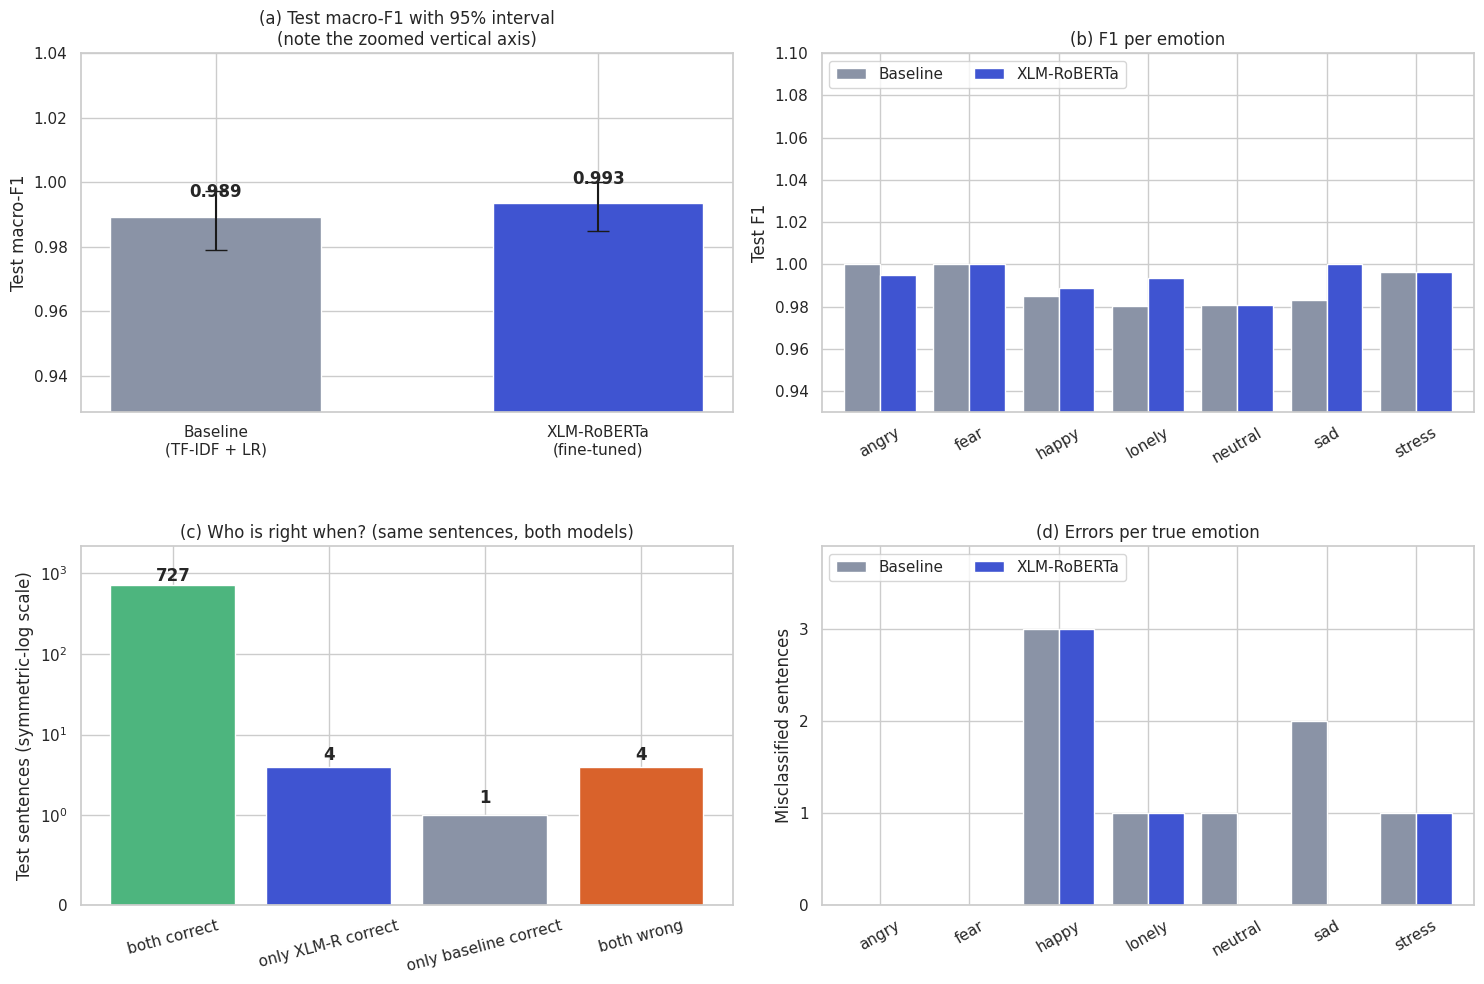

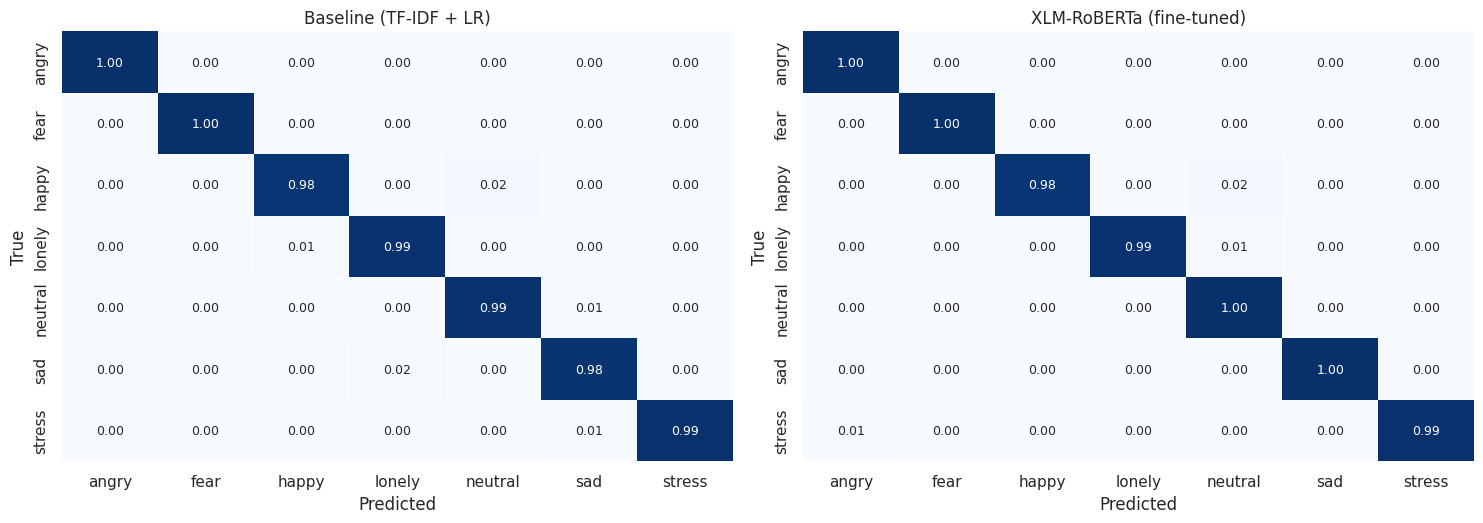

In [29]:
difference = paired_bootstrap_difference(parts["test"]["template_group"], y_test, xlmr_test_pred, base_test_pred, CFG.bootstrap_repeats, CFG.seed)

comparison = pd.DataFrame([
    {"model": "Baseline (TF-IDF + LR)", **base_metrics, "f1_ci_low": base_interval[0], "f1_ci_high": base_interval[2]},
    {"model": "XLM-RoBERTa (fine-tuned)", **xlmr_metrics, "f1_ci_low": xlmr_interval[0], "f1_ci_high": xlmr_interval[2]},
])
display(comparison.round(4))
print(f"Macro-F1 difference, XLM-R minus baseline: median {difference[1]:+.4f}, 95% interval [{difference[0]:+.4f}, {difference[2]:+.4f}]")
print("-> the interval contains 0: no clear winner on this test set." if difference[0] <= 0 <= difference[2]
      else ("-> XLM-R is clearly ahead on this test set." if difference[0] > 0 else "-> the baseline is clearly ahead on this test set."))

both_ok = (xlmr_test_pred == y_test) & (base_test_pred == y_test)
only_x = (xlmr_test_pred == y_test) & (base_test_pred != y_test)
only_b = (xlmr_test_pred != y_test) & (base_test_pred == y_test)
both_bad = (xlmr_test_pred != y_test) & (base_test_pred != y_test)
agreement = pd.Series({"both correct": both_ok.sum(), "only XLM-R correct": only_x.sum(), "only baseline correct": only_b.sum(), "both wrong": both_bad.sum()})

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax = axes[0, 0]
lows = comparison["f1_macro"] - comparison["f1_ci_low"]; highs = comparison["f1_ci_high"] - comparison["f1_macro"]
ax.bar(["Baseline\n(TF-IDF + LR)", "XLM-RoBERTa\n(fine-tuned)"], comparison["f1_macro"], yerr=[lows.clip(lower=0), highs.clip(lower=0)],
       color=[COLORS["baseline"], COLORS["xlmr"]], capsize=8, width=0.55)
ax.set_ylim(max(0, comparison["f1_ci_low"].min() - 0.05), 1.04); ax.set_ylabel("Test macro-F1")
ax.set_title("(a) Test macro-F1 with 95% interval\n(note the zoomed vertical axis)")
for i, v in enumerate(comparison["f1_macro"]): ax.text(i, min(v + 0.006, 1.02), f"{v:.3f}", ha="center", fontweight="bold")

ax = axes[0, 1]
f1_table = pd.DataFrame({"Baseline": base_report.loc[LABELS, "f1-score"], "XLM-RoBERTa": xlmr_report.loc[LABELS, "f1-score"]})
f1_table.plot(kind="bar", ax=ax, color=[COLORS["baseline"], COLORS["xlmr"]], width=0.8)
ax.set_ylim(max(0, f1_table.min().min() - 0.05), 1.1); ax.set_ylabel("Test F1"); ax.tick_params(axis="x", rotation=30)
ax.legend(ncol=2, loc="upper left"); ax.set_title("(b) F1 per emotion")

ax = axes[1, 0]
ax.bar(agreement.index, agreement.values, color=["#4DB57E", COLORS["xlmr"], COLORS["baseline"], COLORS["wrong"]])
for i, v in enumerate(agreement.values): ax.text(i, v * 1.12 + 0.3, str(int(v)), ha="center", fontweight="bold")
ax.set_yscale("symlog", linthresh=1); ax.set_ylim(0, max(agreement.values) * 3)   # keep zero-count categories visible
ax.set_ylabel("Test sentences (symmetric-log scale)"); ax.tick_params(axis="x", rotation=15)
ax.set_title("(c) Who is right when? (same sentences, both models)")

ax = axes[1, 1]
wrong_counts = pd.DataFrame({
    "Baseline": [(base_results["label"].eq(l) & ~base_results["correct"]).sum() for l in LABELS],
    "XLM-RoBERTa": [(xlmr_results["label"].eq(l) & ~xlmr_results["correct"]).sum() for l in LABELS]}, index=LABELS)
wrong_counts.plot(kind="bar", ax=ax, color=[COLORS["baseline"], COLORS["xlmr"]], width=0.8)
ax.margins(y=0.3); ax.legend(ncol=2, loc="upper left")
ax.set_ylabel("Misclassified sentences"); ax.tick_params(axis="x", rotation=30); ax.set_title("(d) Errors per true emotion")
ax.yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout(h_pad=3.5); fig.savefig(COMPARE_OUT / "fig_09_model_comparison.png", dpi=180, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
plot_confusion(y_test, base_test_pred, "Baseline (TF-IDF + LR)", axes[0])
plot_confusion(y_test, xlmr_test_pred, "XLM-RoBERTa (fine-tuned)", axes[1])
plt.tight_layout(); fig.savefig(COMPARE_OUT / "fig_10_confusion_side_by_side.png", dpi=180, bbox_inches="tight"); plt.show()
comparison.to_csv(COMPARE_OUT / "test_comparison.csv", index=False)

### 5.1 Disagreements

Test rows where at least one model is wrong are saved with both predictions and confidence scores.

In [30]:
disagree = xlmr_results[["text", "label", "template_group"]].copy()
disagree["xlmr"], disagree["xlmr_conf"] = xlmr_results["prediction"], xlmr_results["confidence"]
disagree["baseline"], disagree["baseline_conf"] = base_results["prediction"], base_results["confidence"]
disagree["who_is_right"] = np.select([only_x, only_b, both_bad], ["only XLM-R", "only baseline", "neither"], default="both")
shown = disagree[disagree["who_is_right"] != "both"].sort_values("who_is_right")
print(f"{len(shown)} of {len(disagree)} test sentences have at least one wrong model.")
display(shown.head(30))
shown.to_csv(COMPARE_OUT / "disagreements.csv", index=False, encoding="utf-8-sig")

9 of 736 test sentences have at least one wrong model.


,text,label,template_group,xlmr,xlmr_conf,baseline,baseline_conf,who_is_right
212,ការងារថ្ងៃនេះរលូនល្អណាស់ គ្មានបញ្ហាអ្វីទាល់តែស...,happy,1880,neutral,0.998289,neutral,0.610994,neither
228,ការងារថ្ងៃនេះរលូនល្អណាស់ គ្មានបញ្ហាអ្វីទាល់តែសោះ។,happy,1880,neutral,0.997401,neutral,0.667941,neither
278,ការងារថ្ងៃនេះរលូនល្អណាស់ គ្មានបញ្ហាអ្វីទាល់តែស...,happy,1880,neutral,0.997119,neutral,0.528402,neither
373,ទូរស័ព្ទរបស់ខ្ញុំស្ងាត់ច្រៀបពេញមួយថ្ងៃ គ្មានសូ...,lonely,3216,neutral,0.871051,happy,0.290923,neither
409,រង់ចាំមើលលទ្ធផលសិនទៅ មិនទាន់អាចសន្និដ្ឋានអ្វីប...,neutral,3547,neutral,0.997926,sad,0.433968,only XLM-R
519,ខ្ញុំមានអារម្មណ៍ថាខ្លួនឯងគ្មានតម្លៃសម្រាប់នរណា...,sad,4480,sad,0.998478,lonely,0.650066,only XLM-R
541,ខ្ញុំមានអារម្មណ៍ថាខ្លួនឯងគ្មានតម្លៃសម្រាប់នរណា...,sad,4667,sad,0.994557,lonely,0.748894,only XLM-R
734,ខ្ញុំមានអារម្មណ៍ថាមិនអាចទ្រាំទ្រនឹងសម្ពាធការងា...,stress,6422,stress,0.998947,sad,0.327405,only XLM-R
716,រាល់សប្តាហ៍ ចាប់តាំងពីមានបញ្ហាលុយកាក់ខ្ញុំចាប់...,stress,6230,angry,0.856835,stress,0.645443,only baseline


## 6. Independently written sentences

The second evaluation set contains 42 manually labeled Khmer sentences written outside the source corpus, with six examples per emotion. Normalized exact matching is used to confirm that none of them occurs in the prepared dataset.

In [ ]:
# Independently written Khmer test sentences. The labels are human-assigned.
external_tests = [
    # ANGRY
    ("ខំឈរចាំជិតមួយម៉ោង ស្រាប់តែគេមកដល់ក្រោយហើយដើរកាត់មុខធ្វើដូចគ្មានអ្វីកើតឡើង។", "angry"),
    ("ប្រាប់ហើយប្រាប់ទៀតថាកុំយករបស់ខ្ញុំដោយមិនសួរ តែនៅតែធ្វើដដែល!", "angry"),
    ("ខ្ញុំខំធ្វើការម្នាក់ឯង តែដល់ពេលគេសរសើរ បែរជាអ្នកផ្សេងចេញមុខទទួលយកទាំងអស់។", "angry"),
    ("មិនយល់ថាហេតុអ្វីបានជាគាត់ចេះតែស្តីបន្ទោសអ្នកដទៃ ទាំងខ្លួនឯងជាអ្នកធ្វើខុសសោះ។", "angry"),
    ("បើមិនចង់ជួយក៏និយាយត្រង់មក កុំចេះតែសន្យាហើយបាត់ខ្លួនបែបនេះ!", "angry"),
    ("ឃើញគេចោលសំរាមពេញផ្លូវហើយនៅសើចលេងទៀត ពិតជាមិនគិតពីអ្នកដទៃសោះ។", "angry"),

    # FEAR
    ("ឮសំឡេងគោះទ្វារម៉ោងពីរយប់ ខ្ញុំមិនហ៊ានចេញទៅមើលទេ។", "fear"),
    ("មានម៉ូតូមួយគ្រឿងបើកតាមពីក្រោយយូរហើយ ខ្ញុំចាប់ផ្តើមដើរលឿនជាងមុន។", "fear"),
    ("ពេលយន្តហោះរង្គើខ្លាំង ខ្ញុំកាន់ដៃកៅអីជាប់ហើយបិទភ្នែក។", "fear"),
    ("ទើបតែឃើញពស់នៅក្បែរជើង មួយសន្ទុះនោះខ្ញុំឈរគាំងមិនហ៊ានកម្រើក។", "fear"),
    ("ទូរស័ព្ទលោតសារថាមានអ្នកព្យាយាមចូលគណនីខ្ញុំទាំងកណ្តាលយប់។", "fear"),
    ("ភ្លើងក្នុងផ្ទះរលត់ភ្លាមៗ ហើយខ្ញុំឮសំឡេងជើងដើរពីបន្ទប់ខាងក្រោយ។", "fear"),

    # HAPPY
    ("បើកមើលអ៊ីមែលឃើញថាខ្ញុំជាប់អាហារូបករណ៍ ស្ទើរតែមិនជឿភ្នែកខ្លួនឯង។", "happy"),
    ("ថ្ងៃនេះម៉ាក់ញ៉ាំបាយបានច្រើនជាងមុន ហើយញញឹមដាក់ខ្ញុំទៀត។", "happy"),
    ("ក្រោយពីខំរៀនជាច្រើនខែ ទីបំផុតខ្ញុំប្រឡងជាប់ហើយ!", "happy"),
    ("មិត្តភក្តិមកលេងដោយមិនប្រាប់មុន ហើយយកនំដែលខ្ញុំចូលចិត្តមកឱ្យទៀត។", "happy"),
    ("បានជួបប្អូនស្រីវិញក្រោយបែកគ្នាពីរឆ្នាំ យើងអោបគ្នាមិនចង់លែង។", "happy"),
    ("ព្រឹកនេះបើកបង្អួចឃើញមេឃស្អាត ហើយគម្រោងដែលខំធ្វើក៏បានសម្រេចដែរ។", "happy"),

    # LONELY
    ("ចុងសប្តាហ៍មកដល់ទៀតហើយ បើកទូរស័ព្ទមើលក៏មិនដឹងត្រូវហៅអ្នកណាទៅញ៉ាំបាយជាមួយ។", "lonely"),
    ("តាំងពីផ្លាស់មកនៅទីក្រុងថ្មី ខ្ញុំតែងតែញ៉ាំអាហារពេលល្ងាចម្នាក់ឯង។", "lonely"),
    ("ក្នុងបន្ទប់មានតែសំឡេងកង្ហារ ហើយគ្មានអ្នកណាសួរថាថ្ងៃនេះខ្ញុំយ៉ាងម៉េចឡើយ។", "lonely"),
    ("ឃើញគេបង្ហោះរូបជួបជុំគ្នា ខ្ញុំគ្រាន់តែអូសមើលហើយបិទទូរស័ព្ទ។", "lonely"),
    ("ចង់ប្រាប់រឿងល្អៗដែលកើតឡើងថ្ងៃនេះ តែមើលបញ្ជីឈ្មោះហើយមិនដឹងផ្ញើទៅអ្នកណា។", "lonely"),
    ("គេមានគ្នានិយាយលេងពេញតុ ចំណែកខ្ញុំអង្គុយស្ងៀមដូចជាមិនមានអ្នកណាមើលឃើញ។", "lonely"),

    # NEUTRAL
    ("ថ្ងៃស្អែកខ្ញុំមានថ្នាក់រៀននៅម៉ោងប្រាំបីព្រឹក។", "neutral"),
    ("ខ្ញុំទុកកូនសោឡាននៅលើតុខាងមុខបន្ទប់។", "neutral"),
    ("កិច្ចប្រជុំនឹងចាប់ផ្តើមបន្ទាប់ពីសម្រាកអាហារថ្ងៃត្រង់។", "neutral"),
    ("ទូរស័ព្ទនេះមានពីរពណ៌ ហើយម៉ូដែលថ្មីមានអេក្រង់ធំជាងមុន។", "neutral"),
    ("ខ្ញុំទើបប្តូរលេខសម្ងាត់គណនីអ៊ីមែលកាលពីម្សិលមិញ។", "neutral"),
    ("ឡានក្រុងមកដល់ស្ថានីយ៍ម៉ោងប្រាំមួយ ហើយចេញវិញនៅម៉ោងប្រាំមួយកន្លះ។", "neutral"),

    # SAD
    ("ថ្ងៃនេះជាខួបកំណើតប៉ា តែខ្ញុំមិនអាចឮសំឡេងគាត់ម្តងទៀតបានឡើយ។", "sad"),
    ("ខ្ញុំរកឃើញរូបថតចាស់ៗរបស់យើង ហើយអង្គុយមើលវាយូររហូតទឹកភ្នែកហូរ។", "sad"),
    ("ខំថែដើមផ្កានោះជាច្រើនឆ្នាំ តែព្រឹកនេះវាងាប់បាត់ហើយ។", "sad"),
    ("គាត់និយាយថានឹងមិនត្រឡប់មកវិញទេ ខ្ញុំគ្រាន់តែឈរមើលគាត់ដើរចេញទៅ។", "sad"),
    ("ពេលឃើញកៅអីដែលយាយធ្លាប់អង្គុយ ខ្ញុំនឹកដល់ពេលដែលយើងនៅជាមួយគ្នា។", "sad"),
    ("ព្យាយាមអស់ពីសមត្ថភាពហើយ ប៉ុន្តែលទ្ធផលចុងក្រោយនៅតែមិនដូចអ្វីដែលខ្ញុំសង្ឃឹម។", "sad"),

    # STRESS
    ("ថ្ងៃស្អែកត្រូវប្រគល់របាយការណ៍បី ហើយឥឡូវមិនទាន់ធ្វើចប់សូម្បីតែមួយ។", "stress"),
    ("ការងារចាស់មិនទាន់អស់ផង មេផ្ញើការងារថ្មីមកទៀត រហូតមិនដឹងចាប់ពីណាមុន។", "stress"),
    ("បើកកុំព្យូទ័រមកឃើញសារការងាររាប់សិប ហើយគ្រប់គ្នាសុទ្ធតែចង់បានចម្លើយភ្លាមៗ។", "stress"),
    ("ខ្ញុំគិតពីថ្លៃផ្ទះ ថ្លៃសាលា និងបំណុលដែលត្រូវបង់សប្តាហ៍ក្រោយរហូតគេងមិនលក់។", "stress"),
    ("មានតែពីរថ្ងៃទៀតត្រូវប្រឡងប្រាំមុខវិជ្ជា តែមេរៀននៅសល់ច្រើនពេក។", "stress"),
    ("គ្រប់គ្នាចាំឱ្យខ្ញុំសម្រេចចិត្ត តែមានបញ្ហាច្រើនកំពុងកើតឡើងក្នុងពេលតែមួយ។", "stress"),
]
def normalize_for_check(s):
    s = unicodedata.normalize("NFC", str(s))
    return re.sub(r"\s+", "", s).strip("។!? ")

known_texts = set(data["text"].map(normalize_for_check))
external = pd.DataFrame(external_tests, columns=["sentence", "expected"])
external["in_dataset"] = external["sentence"].map(lambda s: normalize_for_check(s) in known_texts)
print("Sentences:", len(external), "| per emotion:", external["expected"].value_counts().to_dict())
print("Found in the original dataset (these would be excluded):", int(external["in_dataset"].sum()))
external = external[~external["in_dataset"]].reset_index(drop=True)

Sentences: 42 | per emotion: {'angry': 6, 'fear': 6, 'happy': 6, 'lonely': 6, 'neutral': 6, 'sad': 6, 'stress': 6}
Found in the original dataset (these would be excluded): 0


### 6.1 Independent-set scores

Both trained models produce probabilities for the 42 sentences. Accuracy, macro-F1, predicted labels, confidence scores, and correctness flags are stored together.

In [32]:
def xlmr_probabilities(texts, batch_size=1):
    """Softmax probabilities of the fine-tuned XLM-R for a list of sentences (shape: n x 7)."""
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            batch = [t.strip() for t in texts[start:start + batch_size]]
            encoded = tokenizer(batch, return_tensors="pt", truncation=True, max_length=CFG.max_length, padding=True).to(model.device)
            outputs.append(torch.softmax(model(**encoded).logits.float(), dim=-1).cpu().numpy())
    return np.vstack(outputs)

def baseline_probabilities(texts):
    return baseline_model.predict_proba(vectorizer.transform([segment_khmer(t.strip()) for t in texts]))

sentences = external["sentence"].tolist()
x_probs, b_probs = xlmr_probabilities(sentences), baseline_probabilities(sentences)
external["xlmr_pred"] = [id2label[i] for i in x_probs.argmax(1)]; external["xlmr_conf"] = x_probs.max(1)
external["base_pred"] = [id2label[i] for i in b_probs.argmax(1)]; external["base_conf"] = b_probs.max(1)
external["xlmr_ok"] = external["xlmr_pred"].eq(external["expected"]); external["base_ok"] = external["base_pred"].eq(external["expected"])

ext_scores = pd.DataFrame([
    {"model": "Baseline (TF-IDF + LR)", "accuracy": external["base_ok"].mean(),
     "macro_f1": f1_score(external["expected"], external["base_pred"], labels=LABELS, average="macro", zero_division=0)},
    {"model": "XLM-RoBERTa (fine-tuned)", "accuracy": external["xlmr_ok"].mean(),
     "macro_f1": f1_score(external["expected"], external["xlmr_pred"], labels=LABELS, average="macro", zero_division=0)},
])
ext_scores["correct"] = [int(external["base_ok"].sum()), int(external["xlmr_ok"].sum())]
ext_scores["of"] = len(external)
display(ext_scores.round(4))
external.to_csv(COMPARE_OUT / "external_khmer_test.csv", index=False, encoding="utf-8-sig")

,model,accuracy,macro_f1,correct,of
0,Baseline (TF-IDF + LR),0.5952,0.5942,25,42
1,XLM-RoBERTa (fine-tuned),0.6667,0.6595,28,42


### 6.2 Independent-set breakdown

Held-out and independent-set accuracy are shown together, followed by per-emotion accuracy and XLM-R confidence on correct and incorrect cases. XLM-R errors are kept with the original sentence for review.

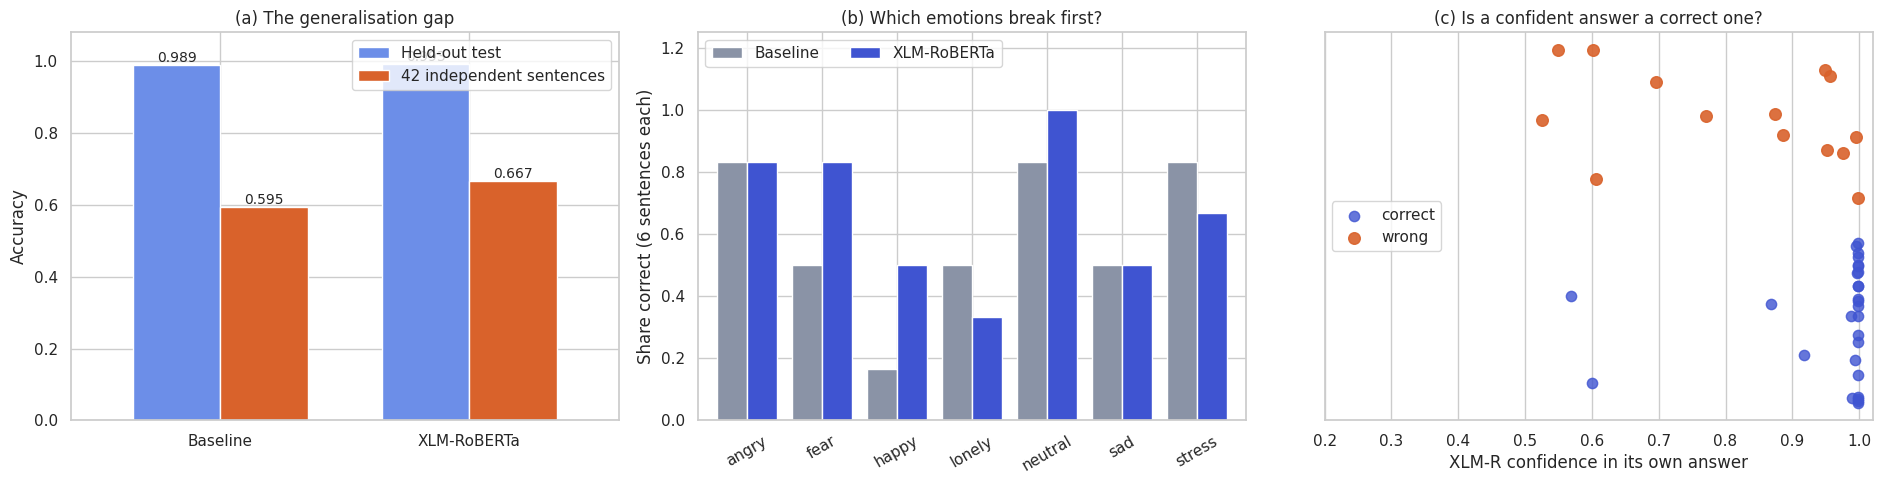

XLM-R got 14 of 42 wrong; 8 of those wrong answers had confidence of at least 85%.

XLM-R's mistakes on the independent sentences:


,expected,xlmr_pred,xlmr_conf,base_pred,sentence
30,sad,happy,0.998531,happy,ថ្ងៃនេះជាខួបកំណើតប៉ា តែខ្ញុំមិនអាចឮសំឡេងគាត់ម្...
21,lonely,angry,0.995841,neutral,ឃើញគេបង្ហោះរូបជួបជុំគ្នា ខ្ញុំគ្រាន់តែអូសមើលហើ...
16,happy,sad,0.976581,sad,បានជួបប្អូនស្រីវិញក្រោយបែកគ្នាពីរឆ្នាំ យើងអោបគ...
37,stress,neutral,0.956923,stress,ការងារចាស់មិនទាន់អស់ផង មេផ្ញើការងារថ្មីមកទៀត រ...
36,stress,neutral,0.952109,stress,ថ្ងៃស្អែកត្រូវប្រគល់របាយការណ៍បី ហើយឥឡូវមិនទាន់...
19,lonely,happy,0.948260,lonely,តាំងពីផ្លាស់មកនៅទីក្រុងថ្មី ខ្ញុំតែងតែញ៉ាំអាហា...
18,lonely,neutral,0.886544,neutral,ចុងសប្តាហ៍មកដល់ទៀតហើយ បើកទូរស័ព្ទមើលក៏មិនដឹងត្...
22,lonely,neutral,0.874756,sad,ចង់ប្រាប់រឿងល្អៗដែលកើតឡើងថ្ងៃនេះ តែមើលបញ្ជីឈ្ម...
33,sad,lonely,0.771077,neutral,គាត់និយាយថានឹងមិនត្រឡប់មកវិញទេ ខ្ញុំគ្រាន់តែឈរ...
31,sad,happy,0.696529,sad,ខ្ញុំរកឃើញរូបថតចាស់ៗរបស់យើង ហើយអង្គុយមើលវាយូររ...


In [33]:
per_class_ext = external.groupby("expected").agg(xlmr=("xlmr_ok", "mean"), baseline=("base_ok", "mean")).reindex(LABELS)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ax = axes[0]
gap = pd.DataFrame({"Held-out test": [base_metrics["accuracy"], xlmr_metrics["accuracy"]],
                    "42 independent sentences": [ext_scores.loc[0, "accuracy"], ext_scores.loc[1, "accuracy"]]}, index=["Baseline", "XLM-RoBERTa"])
gap.plot(kind="bar", ax=ax, color=["#6C8EE8", COLORS["wrong"]], width=0.7, rot=0)
for container in ax.containers: ax.bar_label(container, fmt="%.3f", fontsize=10)
ax.set_ylim(0, 1.08); ax.set_ylabel("Accuracy"); ax.set_title("(a) The generalisation gap")

ax = axes[1]
per_class_ext.rename(columns={"xlmr": "XLM-RoBERTa", "baseline": "Baseline"})[["Baseline", "XLM-RoBERTa"]].plot(
    kind="bar", ax=ax, color=[COLORS["baseline"], COLORS["xlmr"]], width=0.8)
ax.set_ylim(0, 1.25); ax.legend(ncol=2, loc="upper left"); ax.set_xlabel("")
ax.set_ylabel("Share correct (6 sentences each)"); ax.tick_params(axis="x", rotation=30)
ax.set_title("(b) Which emotions break first?")

ax = axes[2]
ax.scatter(external.loc[external["xlmr_ok"], "xlmr_conf"], np.random.default_rng(0).uniform(0.05, 0.45, int(external["xlmr_ok"].sum())), color=COLORS["xlmr"], s=55, alpha=0.8, label="correct")
ax.scatter(external.loc[~external["xlmr_ok"], "xlmr_conf"], np.random.default_rng(1).uniform(0.55, 0.95, int((~external["xlmr_ok"]).sum())), color=COLORS["wrong"], s=70, alpha=0.9, label="wrong")
ax.set_yticks([]); ax.set_xlim(0.2, 1.02); ax.set_xlabel("XLM-R confidence in its own answer")
ax.set_title("(c) Is a confident answer a correct one?"); ax.legend(loc="center left")
plt.tight_layout(); fig.savefig(COMPARE_OUT / "fig_11_external_check.png", dpi=180, bbox_inches="tight"); plt.show()

wrong_x = external.loc[~external["xlmr_ok"]]
if len(wrong_x):
    print(f"XLM-R got {len(wrong_x)} of {len(external)} wrong; {(wrong_x['xlmr_conf'] >= 0.85).sum()} of those wrong answers had confidence of at least 85%.")
print("\nXLM-R's mistakes on the independent sentences:")
display(external.loc[~external["xlmr_ok"], ["expected", "xlmr_pred", "xlmr_conf", "base_pred", "sentence"]].sort_values("xlmr_conf", ascending=False))

## 7. Sample predictions and saved outputs

### 7.1 Single-sentence prediction

`predict_emotion` returns the selected XLM-R label and all seven class probabilities for one Khmer sentence. An optional sentence can be entered in `my_sentence`. The probabilities are model outputs, not psychological or medical assessments.

ខ្ញុំសប្បាយចិត្តណាស់ដែលការងាររបស់ខ្ញុំបានជោគជ័យ។ -> happy (99.9%)
ខ្ញុំមានអារម្មណ៍ភ័យពេលដើរម្នាក់ឯងនៅពេលយប់។ -> fear (99.9%)
ការងារច្រើនពេកធ្វើឱ្យខ្ញុំមានសម្ពាធខ្លាំង។ -> stress (99.9%)


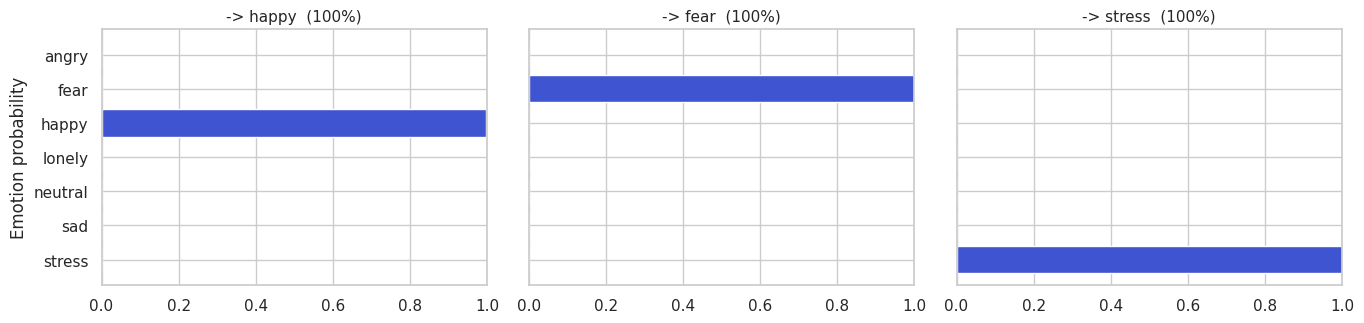

In [34]:
def predict_emotion(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Input must be a non-empty string")
    probs = xlmr_probabilities([text])[0]
    best = int(probs.argmax())
    return {"text": text, "predicted_emotion": id2label[best], "confidence": float(probs[best]),
            "scores": {id2label[i]: float(probs[i]) for i in range(len(LABELS))}}

demo_sentences = [
    "ខ្ញុំសប្បាយចិត្តណាស់ដែលការងាររបស់ខ្ញុំបានជោគជ័យ។",
    "ខ្ញុំមានអារម្មណ៍ភ័យពេលដើរម្នាក់ឯងនៅពេលយប់។",
    "ការងារច្រើនពេកធ្វើឱ្យខ្ញុំមានសម្ពាធខ្លាំង។",
]
my_sentence = ""   # optional custom sentence
if my_sentence.strip():
    demo_sentences.append(my_sentence)

fig, axes = plt.subplots(1, len(demo_sentences), figsize=(4.6 * len(demo_sentences), 3.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, sentence in zip(axes, demo_sentences):
    result = predict_emotion(sentence)
    print(sentence, "->", result["predicted_emotion"], f"({result['confidence']:.1%})")
    ax.barh(LABELS[::-1], [result["scores"][l] for l in LABELS[::-1]],
            color=[COLORS["xlmr"] if l == result["predicted_emotion"] else "#C9D3F5" for l in LABELS[::-1]])
    ax.set_xlim(0, 1); ax.set_title(f"-> {result['predicted_emotion']}  ({result['confidence']:.0%})", fontsize=11)
axes[0].set_ylabel("Emotion probability")
plt.tight_layout(); fig.savefig(XLMR_OUT / "fig_12_demo_predictions.png", dpi=180, bbox_inches="tight"); plt.show()

### 7.2 Run summary

Configuration, fingerprints, audit counts, model metrics, uncertainty intervals, runtime, and independent-set scores are written to `run_summary.json`. Expected output files are checked before the run continues.

In [35]:
def _py(value):
    if isinstance(value, dict): return {k: _py(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [_py(v) for v in value]
    if isinstance(value, (np.floating, np.integer)): return value.item()
    if isinstance(value, Path): return str(value)
    return value

run_summary = _py({
    "split_fingerprint": split_fingerprint,
    "matches_original_fingerprint": split_fingerprint == EXPECTED_FINGERPRINT,
    "audit": {k: v for k, v in audit.items() if k != "generated_suffix_examples"},
    "rows": {name: len(frame) for name, frame in parts.items()},
    "configuration": asdict(CFG),
    "baseline": {"best_C": BEST_C, "test": base_metrics, "macro_f1_95_interval": base_interval.tolist(),
                 "validation": tuning.loc[tuning["C"] == BEST_C].iloc[0].to_dict(), "train_seconds": baseline_minutes * 60},
    "xlmr": {"model": CFG.model_name, "test": xlmr_metrics, "macro_f1_95_interval": xlmr_interval.tolist(),
             "validation": xlmr_val_metrics, "best_validation_macro_f1": xlmr_run["best_metric"],
             "best_checkpoint": xlmr_run["best_checkpoint"], "training_minutes": xlmr_run["training_minutes"], "head_checksum": xlmr_run["head_checksum"]},
    "paired_difference_xlmr_minus_baseline_f1_95_interval": difference.tolist(),
    "external_independent_sentences": ext_scores.to_dict(orient="records"),
})
(OUT_DIR / "run_summary.json").write_text(json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8")

required = [
    OUT_DIR / "fig_01_data_overview.png", OUT_DIR / "fig_02_preprocessing_funnel.png",
    PREP_OUT / "final_template_group_split.parquet", PREP_OUT / "data_audit.json", PREP_OUT / "balance_audit.csv", BASE_OUT / "fig_03_baseline_tuning.png", BASE_OUT / "fig_04_baseline_test.png",
    BASE_OUT / "baseline_tfidf_lr.joblib", XLMR_OUT / "fig_05_token_lengths.png", XLMR_OUT / "fig_06_training_curves.png",
    XLMR_OUT / "fig_07_xlmr_test.png", XLMR_OUT / "xlmr_best_model" / "config.json", XLMR_OUT / "xlmr_test_predictions.parquet",
    COMPARE_OUT / "fig_09_model_comparison.png", COMPARE_OUT / "fig_10_confusion_side_by_side.png",
    COMPARE_OUT / "fig_11_external_check.png", COMPARE_OUT / "external_khmer_test.csv", OUT_DIR / "run_summary.json",
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise RuntimeError(f"Missing outputs: {missing}")
print("All outputs saved in:", OUT_DIR)

All outputs saved in: /content/khmer_work/results


## 8. Results table

Validation, held-out test, and independent-set scores are collected in one table and saved for the report.

In [36]:
summary = pd.DataFrame({
    "Baseline (TF-IDF + LR)": {
        "Validation macro-F1": float(tuning.loc[tuning["C"] == BEST_C, "f1_macro"].iloc[0]),
        "Test accuracy": base_metrics["accuracy"], "Test macro-F1": base_metrics["f1_macro"],
        "Test macro-F1, 95% interval": f"[{base_interval[0]:.3f}, {base_interval[2]:.3f}]",
        "Independent-sentence accuracy": ext_scores.loc[0, "accuracy"], "Independent-sentence macro-F1": ext_scores.loc[0, "macro_f1"],
        "Training time": f"{baseline_minutes*60:.0f} seconds (CPU)"},
    "XLM-RoBERTa (fine-tuned)": {
        "Validation macro-F1": float(xlmr_run["best_metric"]),
        "Test accuracy": xlmr_metrics["accuracy"], "Test macro-F1": xlmr_metrics["f1_macro"],
        "Test macro-F1, 95% interval": f"[{xlmr_interval[0]:.3f}, {xlmr_interval[2]:.3f}]",
        "Independent-sentence accuracy": ext_scores.loc[1, "accuracy"], "Independent-sentence macro-F1": ext_scores.loc[1, "macro_f1"],
        "Training time": f"{xlmr_run['training_minutes']:.1f} minutes (GPU)"},
})
display(summary.style.format(lambda v: f"{v:.3f}" if isinstance(v, float) else v))
summary.to_csv(COMPARE_OUT / "results_summary.csv", encoding="utf-8-sig")


,Baseline (TF-IDF + LR),XLM-RoBERTa (fine-tuned)
Validation macro-F1,0.994,0.995
Test accuracy,0.989,0.993
Test macro-F1,0.989,0.993
"Test macro-F1, 95% interval","[0.979, 0.997]","[0.985, 1.000]"
Independent-sentence accuracy,0.595,0.667
Independent-sentence macro-F1,0.594,0.660
Training time,41 seconds (CPU),13.1 minutes (GPU)


### Limitations

- The source corpus is synthetic and template-heavy. Group separation reduces overlap but does not reproduce naturally written Khmer.
- The independent set has only 42 sentences, so it is a small additional check rather than a stable real-world estimate.
- Each sentence has one label even though emotions can overlap.
- XLM-RoBERTa's Khmer pretraining data are outside the scope of this experiment.
- Model probabilities are not calibrated.
- Automatic Khmer word segmentation can affect the TF-IDF baseline.

Future work should use a larger naturally written Khmer test set, include multi-label cases, compare additional multilingual models, and evaluate confidence calibration.

### References

- Conneau, A. et al. (2020). *Unsupervised Cross-lingual Representation Learning at Scale.* ACL.
- Wolf, T. et al. (2020). *Transformers: State-of-the-Art Natural Language Processing.* EMNLP: System Demonstrations.
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR, 12.
- [`khmer-nltk`](https://pypi.org/project/khmer-nltk/) version 1.6.
- [`FacebookAI/xlm-roberta-base`](https://huggingface.co/FacebookAI/xlm-roberta-base).

## 9. Additional seeds

Seeds 1 and 2 repeat the XLM-R training procedure without changing the data or hyperparameters. Their validation, test, and independent-set scores are kept beside the main seed-42 run. Set `RUN_EXTRA_SEEDS = False` to skip these runs.

In [37]:
RUN_EXTRA_SEEDS = True      # set to False to skip additional runs
EXTRA_SEEDS = (1, 2)

def score_external(m):
    """Accuracy on the independent sentences for any fine-tuned model m (one sentence at a time, like xlmr_probabilities)."""
    m.eval()
    predictions = []
    with torch.no_grad():
        for sentence in external["sentence"]:
            encoded = tokenizer(sentence.strip(), return_tensors="pt", truncation=True, max_length=CFG.max_length).to(m.device)
            predictions.append(int(m(**encoded).logits.float().argmax(-1).item()))
    return float(np.mean([id2label[p] == e for p, e in zip(predictions, external["expected"])]))

seed_rows = [{"seed": CFG.seed, "run": "main run", "head_checksum": HEAD_CHECKSUM,
              "best_val_f1": xlmr_run["best_metric"], "test_accuracy": xlmr_metrics["accuracy"],
              "test_f1_macro": xlmr_metrics["f1_macro"], "independent_accuracy": float(external["xlmr_ok"].mean())}]

if RUN_EXTRA_SEEDS:
    for extra_seed in EXTRA_SEEDS:
        try:
            print(f"\n=== extra run with seed {extra_seed} ===")
            gc.collect(); torch.cuda.empty_cache()
            set_seed(extra_seed)
            extra_model = AutoModelForSequenceClassification.from_pretrained(
                CFG.model_name, num_labels=len(LABELS), label2id=label2id, id2label=id2label)
            extra_checksum = head_checksum(extra_model)
            extra_dir = WORK_DIR / f"xlmr_checkpoints_seed{extra_seed}"
            extra_trainer = Trainer(
                model=extra_model, args=make_training_args(extra_seed, extra_dir),
                train_dataset=encoded_datasets["train"], eval_dataset=encoded_datasets["validation"],
                processing_class=tokenizer, data_collator=data_collator, compute_metrics=compute_metrics,
                callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
            )
            extra_trainer.train()
            extra_trainer.args.group_by_length = False
            extra_output = extra_trainer.predict(encoded_datasets["test"], metric_key_prefix="test")
            extra_metrics = metrics_from_ids(np.asarray(extra_output.label_ids, dtype=int),
                                             np.argmax(extra_output.predictions, axis=-1).astype(int))
            seed_rows.append({"seed": extra_seed, "run": "extra", "head_checksum": extra_checksum,
                              "best_val_f1": float(extra_trainer.state.best_metric),
                              "test_accuracy": extra_metrics["accuracy"], "test_f1_macro": extra_metrics["f1_macro"],
                              "independent_accuracy": score_external(extra_model)})
            del extra_trainer, extra_model, extra_output
            shutil.rmtree(extra_dir, ignore_errors=True)
            gc.collect(); torch.cuda.empty_cache()
        except Exception:
            import traceback
            traceback.print_exc()
            print(f"Extra run with seed {extra_seed} failed; the main results above are unaffected.")
            gc.collect(); torch.cuda.empty_cache()
            break

seed_table = pd.DataFrame(seed_rows)
display(seed_table.round(4))
if len(seed_table) > 1:
    spread = seed_table[["test_accuracy", "test_f1_macro", "independent_accuracy"]].agg(["mean", "std", "min", "max"])
    display(spread.round(4))
    print("Read this as the size of the run-to-run noise: differences between the models (or between two runs) "
          "smaller than this spread should not be interpreted.")
    seed_table.to_csv(COMPARE_OUT / "xlmr_seed_check.csv", index=False)
else:
    print("RUN_EXTRA_SEEDS is False (or no extra run finished): only the main run is shown.")


=== extra run with seed 1 ===


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,0.244100,0.104972,0.973856,0.971696,0.974063,0.972444,0.973796
2,0.036900,0.055043,0.989542,0.989501,0.989968,0.989623,0.989533
3,0.010700,0.021745,0.996078,0.995363,0.995540,0.995406,0.996079



=== extra run with seed 2 ===


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,0.452500,0.170985,0.952941,0.950067,0.950661,0.949917,0.952963
2,0.031900,0.030156,0.993464,0.992460,0.992666,0.992558,0.993470
3,0.008000,0.022062,0.994771,0.993724,0.993724,0.993724,0.994771


,seed,run,head_checksum,best_val_f1,test_accuracy,test_f1_macro,independent_accuracy
0,42,main run,9509.7875,0.9945,0.9932,0.9934,0.6667
1,1,extra,9515.6928,0.9954,0.9932,0.9934,0.6190
2,2,extra,9490.4283,0.9937,0.9932,0.9937,0.7143


,test_accuracy,test_f1_macro,independent_accuracy
mean,0.9932,0.9935,0.6667
std,0.0000,0.0002,0.0476
min,0.9932,0.9934,0.6190
max,0.9932,0.9937,0.7143


Read this as the size of the run-to-run noise: differences between the models (or between two runs) smaller than this spread should not be interpreted.


## 10. Export results

In Colab, result tables and figures are copied to `My Drive/KhmerEmotionFinal/full_submission_results/`. SQLite files and training checkpoints remain temporary. Local checkpoints are removed unless `KEEP_CHECKPOINTS` is enabled.

In [38]:
if IN_COLAB:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    ignore = shutil.ignore_patterns("*.sqlite*", "xlmr_checkpoints*", "" if SAVE_MODEL_TO_DRIVE else "xlmr_best_model")
    shutil.copytree(OUT_DIR, RESULTS_DIR, ignore=ignore, dirs_exist_ok=True)
    copied = [p for p in RESULTS_DIR.rglob("*") if p.is_file()]
    print(f"Copied {len(copied)} files ({sum(p.stat().st_size for p in copied) / 1e6:.1f} MB) to: {RESULTS_DIR}")
else:
    print("Not running in Colab: results stay in", OUT_DIR)

if not KEEP_CHECKPOINTS:
    shutil.rmtree(CHECKPOINT_DIR, ignore_errors=True)
    print("Removed the training checkpoints from the local disk.")
print("\nDone. Now download the executed notebook: File > Download > .ipynb")

Copied 37 files (11.2 MB) to: /content/drive/MyDrive/KhmerEmotionFinal/full_submission_results
Removed the training checkpoints from the local disk.

Done. Now download the executed notebook: File > Download > .ipynb


### Final model copy

The selected XLM-R model and tokenizer are copied into the final Drive results folder.

In [39]:
import shutil
shutil.copytree(FINAL_MODEL_DIR, RESULTS_DIR / "xlmr" / "xlmr_best_model", dirs_exist_ok=True)

PosixPath('/content/drive/MyDrive/KhmerEmotionFinal/full_submission_results/xlmr/xlmr_best_model')